# VGGT + Any4D Dynamic Mask Refinement on Colab

This notebook runs the inference-time experiment: VGGT initial geometry + Any4D scene flow + refined dynamic mask.

## 0. GPU check

In [1]:
!nvidia-smi


Thu Jul  2 19:03:17 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   61C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 1. Clone your repo

In [2]:
%cd /content
!git clone https://github.com/ZexuZang/vggt-demo.git
%cd /content/vggt-demo
!git status


/content
Cloning into 'vggt-demo'...
remote: Enumerating objects: 633, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 633 (delta 0), reused 0 (delta 0), pack-reused 632 (from 2)
Receiving objects: 100% (633/633), 64.75 MiB | 70.38 MiB/s, done.
Resolving deltas: 100% (208/208), done.
/content/vggt-demo
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


## 2. Install VGGT dependencies

In [3]:
%%bash

cd /content/vggt-demo

# install basic dependencies
pip install -r requirements.txt || true
pip install opencv-python matplotlib imageio trimesh gradio huggingface_hub || true

# ensure VGGT source package exists
if [ ! -d "/content/vggt-demo/vggt" ]; then
  echo "No vggt package found. Cloning official VGGT..."
  git clone https://github.com/facebookresearch/vggt.git /content/vggt_official
  cp -r /content/vggt_official/vggt /content/vggt-demo/
fi

# test import
PYTHONPATH=/content/vggt-demo:$PYTHONPATH python -c "from vggt.models.vggt import VGGT; print('VGGT OK')"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.2/61.2 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 779.1/779.1 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.0/7.0 MB 87.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.9/17.9 MB 100.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 410.6/410.6 MB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.1/14.1 MB 115.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 67.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 823.6/823.6 kB 56.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 731.7/731.7 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 MB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.5/56.5 MB 45.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.2/124.2 MB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
xarray-einstats 0.10.0 requires numpy>=2.0, but you have numpy 1.26.1 which is incompatible.
opencv-python 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.1 which is incompatible.
opencv-python-headless 4.13.0.92 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.1 which is incompatible.
tifffile 2026.4.11 requires numpy>=2.0, but you have numpy 1.26.1 which is incompatible.
shap 0.52.0 requires numpy>=2, but you have numpy 1.26.1 which is incompatible.
tobler 0.14.0 requires numpy>=2.0, but you have numpy 1.26.1 which is incompatible.
cupy-cuda12x 14.0.1 requires numpy<2.6,>=2.0, but you have numpy 1.26.1 which is incompatible.
rasterio 1.5.0 requires numpy>=2, but you have numpy 1.26.1 which is incompatible.
jax 0.7.2 requires numpy>=2.0, but you have numpy 1.26.1 w

## 3. Clone and install Any4D

In [4]:
%cd /content/vggt-demo
!mkdir -p third_party
![ -d third_party/Any4D ] || git clone https://github.com/Any-4D/Any4D.git third_party/Any4D
%cd /content/vggt-demo/third_party/Any4D
!pip install -e ".[all]"
!mkdir -p checkpoints
![ -f checkpoints/any4d_4v_combined.pth ] || wget -P checkpoints https://huggingface.co/airlabshare/any4d-checkpoint/resolve/main/any4d_4v_combined.pth


/content/vggt-demo
Cloning into 'third_party/Any4D'...
remote: Enumerating objects: 995, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 995 (delta 1), reused 1 (delta 1), pack-reused 980 (from 1)
Receiving objects: 100% (995/995), 146.70 MiB | 49.21 MiB/s, done.
Resolving deltas: 100% (54/54), done.
/content/vggt-demo/third_party/Any4D
Obtaining file:///content/vggt-demo/third_party/Any4D
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Cloning https://github.com/JayKarhade/UniCeption.git (to revision dev/any4d) to /tmp/pip-install-ng83y8xq/uniception_9aaf24d3d6e8494aa1d63a91fab27a33
  Running command git clone --filter=blob:none --quiet https://github.com/JayKarhade/UniCeption.git /tmp/pip-install-ng83y8xq/uniception_9aaf24d3d6e8494aa1d63a91fab27a33
  Running 

## 4. Prepare input frames

Put frames in `/content/vggt-demo/data/stroller_frames` using Colab upload or Google Drive.

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%cd /content/vggt-demo

!mkdir -p outputs

!find "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby" -maxdepth 1 -type f -name "*.jpg" | head
!find "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby" -maxdepth 1 -type f -name "*.jpg" | wc -l

/content/vggt-demo
/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby/00000.jpg
/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby/00001.jpg
/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby/00002.jpg
/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby/00003.jpg
/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby/00004.jpg
/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby/00005.jpg
/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby/00006.jpg
/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby/00007.jpg
/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby/00008.jpg
/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby/00009.jpg
91


## 5. Export VGGT predictions

In [ ]:
%cd /content/vggt-demo

!PYTHONPATH=/content/vggt-demo:$PYTHONPATH python scripts/any4d_mask/export_vggt_predictions.py \
  --image_dir "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby" \
  --output_npz outputs/vggt_pred.npz \
  --max_frames 16


/content/vggt-demo
[VGGT] Loading facebook/VGGT-1B
config.json: 100% 62.0/62.0 [00:00<00:00, 570kB/s]
model.safetensors: 100% 5.03G/5.03G [00:13<00:00, 371MB/s]
[VGGT] Loading 16 frames
[VGGT] Inference
/content/vggt-demo/scripts/any4d_mask/export_vggt_predictions.py:85: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=dtype, enabled=autocast_enabled):
[VGGT] Saved outputs/vggt_pred.npz
{
  "image_paths": [
    16
  ],
  "preprocessed_hw": [
    2
  ],
  "extrinsic": [
    16,
    3,
    4
  ],
  "intrinsic": [
    16,
    3,
    3
  ],
  "depth": [
    16,
    294,
    518,
    1
  ],
  "depth_conf": [
    16,
    294,
    518
  ],
  "point_map": [
    16,
    294,
    518,
    3
  ],
  "point_conf": [
    16,
    294,
    518
  ],
  "point_map_by_unprojection": [
    16,
    294,
    518,
    3
  ]
}


## 6. Export Any4D predictions

In [ ]:
%%bash

cd /content/vggt-demo

python - <<'PY'
from pathlib import Path

p = Path("scripts/any4d_mask/export_any4d_predictions.py")
txt = p.read_text()

old = "    from scripts.demo_inference import init_inference_model, sample_inference"

new = """    import importlib.util

    demo_path = any4d_root / "scripts" / "demo_inference.py"
    if not demo_path.exists():
        raise FileNotFoundError(f"Cannot find Any4D demo_inference.py at: {demo_path}")

    spec = importlib.util.spec_from_file_location("any4d_demo_inference", str(demo_path))
    demo_mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(demo_mod)

    init_inference_model = demo_mod.init_inference_model
    sample_inference = demo_mod.sample_inference"""

if old not in txt:
    print("Old import line not found. Maybe already patched.")
else:
    txt = txt.replace(old, new)
    p.write_text(txt)
    print("Patched export_any4d_predictions.py successfully.")
PY

grep -n "demo_path\|init_inference_model\|sample_inference" scripts/any4d_mask/export_any4d_predictions.py | head -20

Patched export_any4d_predictions.py successfully.
75:    demo_path = any4d_root / "scripts" / "demo_inference.py"
76:    if not demo_path.exists():
77:        raise FileNotFoundError(f"Cannot find Any4D demo_inference.py at: {demo_path}")
79:    spec = importlib.util.spec_from_file_location("any4d_demo_inference", str(demo_path))
83:    init_inference_model = demo_mod.init_inference_model
84:    sample_inference = demo_mod.sample_inference
120:    model = init_inference_model(
142:    pred_result = sample_inference(


In [ ]:
%cd /content/vggt-demo

!ls third_party/Any4D/scripts | head
!ls third_party/Any4D/scripts/demo_inference.py
!ls -lh third_party/Any4D/checkpoints/any4d_4v_combined.pth

/content/vggt-demo
any4d_gradio.py
demo_inference.py
third_party/Any4D/scripts/demo_inference.py
-rw-r--r-- 1 root root 7.2G Jun 26 21:45 third_party/Any4D/checkpoints/any4d_4v_combined.pth


In [ ]:
%%bash

cd /content/vggt-demo/third_party/Any4D

mkdir -p any4d/external

if [ ! -d "any4d/external/MoGe" ]; then
  git clone https://github.com/microsoft/MoGe.git any4d/external/MoGe
fi

ls -lah any4d/external/MoGe

total 96K
drwxr-xr-x 8 root root 4.0K Jun 26 21:14 .
drwxr-xr-x 3 root root 4.0K Jun 26 21:14 ..
drwxr-xr-x 2 root root 4.0K Jun 26 21:14 assets
drwxr-xr-x 2 root root 4.0K Jun 26 21:14 baselines
-rw-r--r-- 1 root root 1.4K Jun 26 21:14 CHANGELOG.md
-rw-r--r-- 1 root root  444 Jun 26 21:14 CODE_OF_CONDUCT.md
drwxr-xr-x 4 root root 4.0K Jun 26 21:14 configs
drwxr-xr-x 2 root root 4.0K Jun 26 21:14 docs
drwxr-xr-x 2 root root 4.0K Jun 26 21:14 example_images
-rw-r--r-- 1 root root 7.0K Jun 26 21:14 .gitignore
-rw-r--r-- 1 root root  13K Jun 26 21:14 LICENSE
drwxr-xr-x 7 root root 4.0K Jun 26 21:14 moge
-rw-r--r-- 1 root root  830 Jun 26 21:14 pyproject.toml
-rw-r--r-- 1 root root  121 Jun 26 21:14 pyrightconfig.json
-rw-r--r-- 1 root root 9.2K Jun 26 21:14 README.md
-rw-r--r-- 1 root root  592 Jun 26 21:14 requirements.txt
-rw-r--r-- 1 root root 2.6K Jun 26 21:14 SECURITY.md
-rw-r--r-- 1 root root 1.3K Jun 26 21:14 SUPPORT.md


In [ ]:
%%bash

cd /content/vggt-demo/third_party/Any4D/any4d/external/MoGe

pip install -e . || true
pip install huggingface_hub safetensors einops opencv-python matplotlib pillow imageio || true

Obtaining file:///content/vggt-demo/third_party/Any4D/any4d/external/MoGe
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Checking if build backend supports build_editable: started
  Checking if build backend supports build_editable: finished with status 'done'
  Getting requirements to build editable: started
  Getting requirements to build editable: finished with status 'done'
  Preparing editable metadata (pyproject.toml): started
  Preparing editable metadata (pyproject.toml): finished with status 'done'
  Using cached utils3d-0.0.2-py3-none-any.whl
  Building editable for moge (pyproject.toml): started
  Building editable for moge (pyproject.toml): finished with status 'done'
  Created wheel for moge: filename=moge-1.0.0-0.editable-py3-none-any.whl size=11523 sha256=988dc7283042abdabcc5731126a7770ae9900a7f15b1077899c048d5fa4e3b94
  Stored in directory: /tmp/pip-ephem-wheel-cache-2srlvwhx/wheels/9a/d9/b2/2768239f0fb448794025e6

In [ ]:
%cd /content/vggt-demo/third_party/Any4D

!PYTHONPATH=/content/vggt-demo/third_party/Any4D:/content/vggt-demo/third_party/Any4D/scripts:/content/vggt-demo:$PYTHONPATH python /content/vggt-demo/scripts/any4d_mask/export_any4d_predictions.py \
  --any4d_root /content/vggt-demo/third_party/Any4D \
  --image_dir "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby" \
  --checkpoint_path /content/vggt-demo/third_party/Any4D/checkpoints/any4d_4v_combined.pth \
  --output_npz /content/vggt-demo/outputs/any4d_pred.npz \
  --ref_img_idx 0 \
  --start_idx 0 \
  --end_idx 16

/content/vggt-demo/third_party/Any4D
[Any4D] Loading model
Initializing <class 'any4d.models.any4d.model.Any4D'> with kwargs: {'torch_hub_force_reload': False, 'pretrained_checkpoint_path': None, 'load_specific_pretrained_submodules': False, 'specific_pretrained_submodules': [], 'name': 'any4d', 'encoder_config': {'encoder_str': 'dinov2', 'name': 'dinov2_large', 'data_norm_type': 'dinov2', 'size': 'large', 'with_registers': False, 'uses_torch_hub': False, 'gradient_checkpointing': False}, 'info_sharing_config': {'model_type': 'alternating_attention', 'model_return_type': 'intermediate_features', 'custom_positional_encoding': None, 'module_args': {'name': 'aat_24_layers_ifr', 'indices': [11, 17], 'norm_intermediate': True, 'size': '24_layers', 'depth': 24, 'distinguish_ref_and_non_ref_views': True, 'gradient_checkpointing': False}}, 'pred_head_config': {'adaptor_config': {'input_dim': 6, 'scene_rep_dim': 4, 'type': 'raydirs+depth+pose+confidence+mask', 'scene_rep_type': 'raydirs+depth+p

## 7. Fuse Any4D motion cue with VGGT confidence

In [ ]:
%cd /content/vggt-demo

!python scripts/any4d_mask/refine_dynamic_mask.py \
  --vggt_npz outputs/vggt_pred.npz \
  --any4d_npz outputs/any4d_pred.npz \
  --image_dir "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby" \
  --output_dir outputs/refined_mask \
  --ref_idx 0 \
  --aggregate max \
  --dynamic_thresh 0.55 \
  --static_weight_thresh 0.45

/content/vggt-demo
{
  "target_hw": [
    294,
    518
  ],
  "ref_idx": 0,
  "image_path": "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby/00000.jpg",
  "aggregate": "max",
  "dynamic_thresh": 0.55,
  "conf_thresh": 0.25,
  "static_weight_thresh": 0.45,
  "dynamic_ratio": 0.10307829695584797,
  "static_ba_ratio": 0.22739868148031414,
  "exclude_ratio": 0.6171236834502141
}
[MaskRefine] Saved results to outputs/refined_mask


In [ ]:
%cd /content/vggt-demo

!python scripts/any4d_mask/cotracker_any4d_dynamic_points.py \
  --image_dir "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby" \
  --any4d_npz outputs/any4d_pred.npz \
  --dynamic_prior_path outputs/refined_mask/dynamic_probability.npy \
  --static_weight_path outputs/refined_mask/static_weight.npy \
  --output_dir outputs/cotracker_any4d_points \
  --max_frames 16 \
  --grid_size 35 \
  --resize_max_side 768 \
  --point_dynamic_thresh 0.55 \
  --min_visible_ratio 0.35 \
  --point_radius 18 \
  --blur_sigma 7 \
  --mask_thresh 0.35 \
  --combine_with_prior max

/content/vggt-demo
[CoTracker] Loading cotracker3_offline from torch.hub
Downloading: "https://github.com/facebookresearch/co-tracker/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://huggingface.co/facebook/cotracker3/resolve/main/scaled_offline.pth" to /root/.cache/torch/hub/checkpoints/scaled_offline.pth
100% 97.2M/97.2M [00:00<00:00, 335MB/s]
[CoTracker] Running grid_size=35, video=(1, 8, 3, 432, 768)
{
  "image_dir": "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby",
  "any4d_npz": "outputs/any4d_pred.npz",
  "dynamic_prior_path": "outputs/refined_mask/dynamic_probability.npy",
  "static_weight_path": "outputs/refined_mask/static_weight.npy",
  "output_dir": "outputs/cotracker_any4d_points",
  "num_frames": 8,
  "track_hw": [
    432,
    768
  ],
  "original_hw": [
    512,
    910
  ],
  "resize_scale": 0.843956043956044,
  "grid_size": 35,
  "num_representative_points": 1225,
  "num_dynamic_points": 122,
  "dynamic_point_ratio": 

In [ ]:
%cd /content/vggt-demo

!python scripts/any4d_mask/cotracker_any4d_dynamic_points.py \
  --image_dir "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby" \
  --any4d_npz outputs/any4d_pred.npz \
  --static_weight_path outputs/refined_mask/static_weight.npy \
  --output_dir outputs/cotracker_any4d_points_flow_only \
  --max_frames 16 \
  --grid_size 45 \
  --resize_max_side 768 \
  --point_dynamic_thresh 0.55 \
  --min_visible_ratio 0.35 \
  --point_radius 20 \
  --blur_sigma 6 \
  --mask_thresh 0.30 \
  --combine_with_prior none

/content/vggt-demo
[CoTracker] Loading cotracker3_offline from torch.hub
Using cache found in /root/.cache/torch/hub/facebookresearch_co-tracker_main
[CoTracker] Running grid_size=45, video=(1, 8, 3, 432, 768)
{
  "image_dir": "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby",
  "any4d_npz": "outputs/any4d_pred.npz",
  "dynamic_prior_path": null,
  "static_weight_path": "outputs/refined_mask/static_weight.npy",
  "output_dir": "outputs/cotracker_any4d_points_flow_only",
  "num_frames": 8,
  "track_hw": [
    432,
    768
  ],
  "original_hw": [
    512,
    910
  ],
  "resize_scale": 0.843956043956044,
  "grid_size": 45,
  "num_representative_points": 2025,
  "num_dynamic_points": 194,
  "dynamic_point_ratio": 0.09580246913580247,
  "dynamic_mask_ratio": 0.1362033420138889,
  "static_ba_ratio": 0.2157570167824074,
  "motion_source_key": "scene_flow_ref_to_targets",
  "point_dynamic_thresh": 0.55,
  "min_visible_ratio": 0.35,
  "point_radius": 20,
  "blur_sig

In [ ]:
# 修改1：把morph_kernel 改小
%cd /content/vggt-demo

!python scripts/any4d_mask/refine_dynamic_mask.py \
  --vggt_npz outputs/vggt_pred.npz \
  --any4d_npz outputs/any4d_pred.npz \
  --image_dir "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby" \
  --output_dir outputs/refined_mask_k1 \
  --ref_idx 0 \
  --aggregate max \
  --dynamic_thresh 0.60 \
  --static_weight_thresh 0.45 \
  --morph_kernel 1 \
  --dynamic_boost_from_uncertainty 0.05

/content/vggt-demo
{
  "target_hw": [
    294,
    518
  ],
  "ref_idx": 0,
  "image_path": "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby/00000.jpg",
  "aggregate": "max",
  "dynamic_thresh": 0.6,
  "conf_thresh": 0.25,
  "static_weight_thresh": 0.45,
  "dynamic_ratio": 0.1000971817298348,
  "static_ba_ratio": 0.22560607254484805,
  "exclude_ratio": 0.617366637774801
}
[MaskRefine] Saved results to outputs/refined_mask_k1


In [ ]:
# 修改2：提高动态阈值
%cd /content/vggt-demo

!python scripts/any4d_mask/refine_dynamic_mask.py \
  --vggt_npz outputs/vggt_pred.npz \
  --any4d_npz outputs/any4d_pred.npz \
  --image_dir "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby" \
  --output_dir outputs/refined_mask_t065 \
  --ref_idx 0 \
  --aggregate max \
  --dynamic_thresh 0.65 \
  --static_weight_thresh 0.45 \
  --morph_kernel 3 \
  --dynamic_boost_from_uncertainty 0.05

/content/vggt-demo
{
  "target_hw": [
    294,
    518
  ],
  "ref_idx": 0,
  "image_path": "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby/00000.jpg",
  "aggregate": "max",
  "dynamic_thresh": 0.65,
  "conf_thresh": 0.25,
  "static_weight_thresh": 0.45,
  "dynamic_ratio": 0.0988101804428335,
  "static_ba_ratio": 0.22651222651222652,
  "exclude_ratio": 0.6166377748010401
}
[MaskRefine] Saved results to outputs/refined_mask_t065


In [ ]:
# 修改3：减少 uncertainty 对 dynamic mask 的影响，纯粹依赖Any4D
%cd /content/vggt-demo

!python scripts/any4d_mask/refine_dynamic_mask.py \
  --vggt_npz outputs/vggt_pred.npz \
  --any4d_npz outputs/any4d_pred.npz \
  --image_dir "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby" \
  --output_dir outputs/refined_mask_motion_only \
  --ref_idx 0 \
  --aggregate max \
  --dynamic_thresh 0.60 \
  --static_weight_thresh 0.45 \
  --morph_kernel 1 \
  --dynamic_boost_from_uncertainty 0.0

/content/vggt-demo
{
  "target_hw": [
    294,
    518
  ],
  "ref_idx": 0,
  "image_path": "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby/00000.jpg",
  "aggregate": "max",
  "dynamic_thresh": 0.6,
  "conf_thresh": 0.25,
  "static_weight_thresh": 0.45,
  "dynamic_ratio": 0.09934861975678302,
  "static_ba_ratio": 0.22560607254484805,
  "exclude_ratio": 0.6173141071100254
}
[MaskRefine] Saved results to outputs/refined_mask_motion_only


## point level

In [ ]:
%cd /content/vggt-demo

!python scripts/any4d_mask/cotracker_any4d_dynamic_points.py \
  --image_dir "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby" \
  --any4d_npz outputs/any4d_pred.npz \
  --output_dir outputs/cotracker_any4d_points_bg \
  --max_frames 16 \
  --grid_size 45 \
  --resize_max_side 768 \
  --point_dynamic_thresh 0.60 \
  --min_visible_ratio 0.40 \
  --use_bg_motion_residual \
  --bg_model affine \
  --bg_residual_score_thresh 0.40 \
  --bg_residual_px_thresh 1.5 \
  --bg_static_candidate_percentile 45 \
  --point_radius 1 \
  --point_vis_radius 3 \
  --blur_sigma 0 \
  --mask_thresh 0.30 \
  --combine_with_prior none

/content/vggt-demo
[CoTracker] Loading cotracker3_offline from torch.hub
Using cache found in /root/.cache/torch/hub/facebookresearch_co-tracker_main
[CoTracker] Running grid_size=45, video=(1, 8, 3, 432, 768)
[BGResidual] Frame 1: model=affine, candidates=985, inlier_ratio=0.857, median_res=1.002px
[BGResidual] Frame 2: model=affine, candidates=957, inlier_ratio=0.743, median_res=2.459px
[BGResidual] Frame 3: model=affine, candidates=903, inlier_ratio=0.507, median_res=4.362px
[BGResidual] Frame 4: model=affine, candidates=857, inlier_ratio=0.364, median_res=6.805px
[BGResidual] Frame 5: model=affine, candidates=801, inlier_ratio=0.250, median_res=8.416px
[BGResidual] Frame 6: model=affine, candidates=757, inlier_ratio=0.293, median_res=6.599px
[BGResidual] Frame 7: model=affine, candidates=733, inlier_ratio=0.329, median_res=5.609px
/content/vggt-demo/scripts/any4d_mask/cotracker_any4d_dynamic_points.py:240: RuntimeWarning: All-NaN slice encountered
  bg_residual_px = np.nanmedian(pe

VGGT depth-aware point connected components

In [ ]:
%cd /content/vggt-demo

!python scripts/any4d_mask/cotracker_any4d_dynamic_points.py \
  --image_dir "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby" \
  --any4d_npz outputs/any4d_pred.npz \
  --vggt_npz outputs/vggt_pred.npz \
  --output_dir outputs/cotracker_any4d_points_depth_cc_prop_legs \
  --max_frames 16 \
  --grid_size 45 \
  --resize_max_side 768 \
  --local_resample \
  --local_step 5 \
  --local_pad 55 \
  --local_link_radius 28 \
  --local_seed_thresh 0.45 \
  --local_motion_gate 0.12 \
  --local_depth_gate 0.35 \
  --local_max_queries 3500 \
  --point_dynamic_thresh 0.50 \
  --min_visible_ratio 0.30 \
  --use_bg_motion_residual \
  --bg_model affine \
  --bg_residual_score_thresh 0.30 \
  --bg_residual_px_thresh 1.0 \
  --use_depth_cc \
  --cc_radius 12 \
  --cc_depth_gate 0.35 \
  --cc_score_gate 0.60 \
  --cc_candidate_score_thresh 0.20 \
  --cc_min_component_points 2 \
  --cc_min_dynamic_points 1 \
  --cc_min_dynamic_ratio 0.05 \
  --cc_min_mean_score 0.15 \
  --cc_propagate \
  --point_radius 1 \
  --point_vis_radius 3 \
  --blur_sigma 0 \
  --mask_thresh 0.30 \
  --combine_with_prior none

/content/vggt-demo
[CoTracker] Loading cotracker3_offline from torch.hub
Using cache found in /root/.cache/torch/hub/facebookresearch_co-tracker_main
[CoTracker] Running grid_size=45, video=(1, 8, 3, 432, 768)
[LocalResample] Building preliminary dynamic seed points
[LocalResample] Found 1 local dynamic boxes: [(149, 0, 467, 431)]
[LocalResample] Local query points after filters: 1392
[CoTracker] Loading cotracker3_offline for local queries
Using cache found in /root/.cache/torch/hub/facebookresearch_co-tracker_main
[CoTracker] Running local queries: 1392 points
[LocalResample] Total points after local resampling: 3417
[BGResidual] Frame 1: model=affine, candidates=1522, inlier_ratio=0.940, median_res=1.099px
[BGResidual] Frame 2: model=affine, candidates=1489, inlier_ratio=0.691, median_res=2.414px
[BGResidual] Frame 3: model=affine, candidates=1420, inlier_ratio=0.393, median_res=5.116px
[BGResidual] Frame 4: model=affine, candidates=1357, inlier_ratio=0.354, median_res=8.102px
[BGRe

综合打分的策略

In [ ]:
%cd /content/vggt-demo

!python scripts/any4d_mask/cotracker_any4d_dynamic_points.py \
  --image_dir "/content/drive/MyDrive/custom4d_dataset/custom4d_unzipped/images/any4d_baby" \
  --any4d_npz outputs/any4d_pred.npz \
  --vggt_npz outputs/vggt_pred.npz \
  --output_dir outputs/cotracker_any4d_points_temporal_leg \
  --max_frames 16 \
  --grid_size 45 \
  --resize_max_side 768 \
  --local_resample \
  --local_step 5 \
  --local_pad 65 \
  --local_link_radius 28 \
  --local_seed_thresh 0.45 \
  --local_motion_gate 0.08 \
  --local_depth_gate 0.35 \
  --local_max_queries 3500 \
  --point_dynamic_thresh 0.50 \
  --temporal_any4d_thresh 0.30 \
  --min_visible_ratio 0.30 \
  --use_bg_motion_residual \
  --bg_model affine \
  --bg_residual_reduce max \
  --bg_residual_score_thresh 0.30 \
  --bg_residual_px_thresh 0.8 \
  --use_temporal_or \
  --temporal_min_bg_frames 1 \
  --temporal_min_visible_frames 2 \
  --use_depth_cc \
  --cc_radius 10 \
  --cc_depth_gate 0.25 \
  --cc_score_gate 0.60 \
  --cc_candidate_score_thresh 0.20 \
  --cc_min_component_points 2 \
  --cc_min_dynamic_points 1 \
  --cc_min_dynamic_ratio 0.05 \
  --cc_min_mean_score 0.15 \
  --cc_propagate \
  --point_radius 1 \
  --point_vis_radius 3 \
  --blur_sigma 0 \
  --mask_thresh 0.30 \
  --combine_with_prior none

/content/vggt-demo
[CoTracker] Loading cotracker3_offline from torch.hub
Using cache found in /root/.cache/torch/hub/facebookresearch_co-tracker_main
[CoTracker] Running grid_size=45, video=(1, 16, 3, 432, 768)
[LocalResample] Building preliminary dynamic seed points
[LocalResample] Found 1 local dynamic boxes: [(139, 0, 477, 431)]
[LocalResample] Local query points after filters: 1334
[CoTracker] Loading cotracker3_offline for local queries
Using cache found in /root/.cache/torch/hub/facebookresearch_co-tracker_main
[CoTracker] Running local queries: 1334 points
[LocalResample] Total points after local resampling: 3359
[BGResidual] Frame 1: model=affine, candidates=1492, inlier_ratio=0.958, median_res=1.103px
[BGResidual] Frame 2: model=affine, candidates=1461, inlier_ratio=0.606, median_res=2.807px
[BGResidual] Frame 3: model=affine, candidates=1388, inlier_ratio=0.407, median_res=4.332px
[BGResidual] Frame 4: model=affine, candidates=1333, inlier_ratio=0.342, median_res=7.653px
[BGR

In [ ]:
import shutil
from pathlib import Path
from google.colab import files

target_dir = Path("/content/vggt-demo/outputs/cotracker_any4d_points_temporal_leg")
zip_base = Path("/content/cotracker_any4d_points_temporal_leg")

assert target_dir.exists(), f"Folder not found: {target_dir}"

shutil.make_archive(str(zip_base), "zip", root_dir=target_dir)

files.download(str(zip_base) + ".zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 8. Visualize outputs

In [ ]:
from pathlib import Path
from IPython.display import display
from PIL import Image

out = Path('/content/vggt-demo/outputs/cotracker_any4d_point_level')
for name in ['motion_probability.png','vggt_confidence.png','dynamic_probability.png','static_weight.png','refined_dynamic_mask.png','static_ba_mask.png','refined_dynamic_overlay.png','static_ba_overlay.png']:
    p = out / name
    if p.exists():
        print(name)
        display(Image.open(p))


In [ ]:
import shutil
from google.colab import files

outputs_dir = "/content/vggt-demo/outputs"
zip_path = "/content/vggt_outputs"

shutil.make_archive(zip_path, "zip", outputs_dir)

files.download(zip_path + ".zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Bonn + DROID-W Quick Test

This section is for testing whether your VGGT + Any4D + CoTracker dynamic reliability can produce per-frame `static_weight` maps for DROID-W.

Important: for a real DROID-W experiment, VGGT / Any4D / CoTracker must run on the **same Bonn sequence frames** used by DROID-W. Do not use the old `any4d_baby` paths for this test.


In [29]:
# ===== Clear RAM / GPU memory and reset Bonn path =====
%reset -f

import os
import gc
from pathlib import Path

try:
    import torch
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()
except Exception as e:
    print("Torch cache clear skipped:", e)

gc.collect()

# Rebuild Bonn path after reset
BONN_SEQ_DIR = Path("/content/drive/MyDrive/Datasets/Bonn/person_tracking")
if not BONN_SEQ_DIR.exists():
    fallback = Path("/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking")
    if fallback.exists():
        BONN_SEQ_DIR = fallback

RGB_DIR = BONN_SEQ_DIR / "rgb"

assert RGB_DIR.exists(), f"RGB folder not found: {RGB_DIR}"

os.environ["RGB_DIR"] = str(RGB_DIR)

print("Memory cleanup done.")
print("BONN_SEQ_DIR =", BONN_SEQ_DIR)
print("RGB_DIR =", RGB_DIR)

!nvidia-smi
!find "$RGB_DIR" -maxdepth 1 -type f | wc -l

Memory cleanup done.
BONN_SEQ_DIR = /content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking
RGB_DIR = /content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb
Thu Jul  2 20:15:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8             10W /   70W |       3MiB /

In [30]:
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive', force_remount=False)

SEQ_NAME = "person_tracking"

# Bonn sequence folder. Use the renamed folder first; otherwise fallback to the original unzip folder.
BONN_SEQ_DIR = Path("/content/drive/MyDrive/Datasets/Bonn/person_tracking")
if not BONN_SEQ_DIR.exists():
    fallback = Path("/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking")
    if fallback.exists():
        BONN_SEQ_DIR = fallback

RGB_DIR = BONN_SEQ_DIR / "rgb"

print("BONN_SEQ_DIR:", BONN_SEQ_DIR)
print("RGB_DIR:", RGB_DIR)

assert RGB_DIR.exists(), f"RGB folder not found: {RGB_DIR}"

print("RGB examples:")
!find "$RGB_DIR" -maxdepth 1 -type f | head
!find "$RGB_DIR" -maxdepth 1 -type f | wc -l


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BONN_SEQ_DIR: /content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking
RGB_DIR: /content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb
RGB examples:
/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb/1548265882.53315.png
/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb/1548265882.66521.png
/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb/1548265882.56656.png
/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb/1548265882.60003.png
/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb/1548265882.76567.png
/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb/1548265882.49963.png
/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb/1548265882.73218.png
/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb/1548265882.69867.png


### 10.1 Export VGGT predictions on Bonn frames

In [31]:
## 路径修复
from pathlib import Path
from google.colab import drive
import os

drive.mount("/content/drive", force_remount=False)

SEQ_NAME = "person_tracking"

BONN_SEQ_DIR = Path("/content/drive/MyDrive/Datasets/Bonn/person_tracking")

if not BONN_SEQ_DIR.exists():
    fallback = Path("/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking")
    if fallback.exists():
        BONN_SEQ_DIR = fallback

RGB_DIR = BONN_SEQ_DIR / "rgb"

print("BONN_SEQ_DIR =", BONN_SEQ_DIR)
print("RGB_DIR =", RGB_DIR)
print("RGB_DIR exists:", RGB_DIR.exists())

assert RGB_DIR.exists(), f"RGB folder not found: {RGB_DIR}"

# 关键：把 Python 变量写入 shell 环境变量
os.environ["BONN_SEQ_DIR"] = str(BONN_SEQ_DIR)
os.environ["RGB_DIR"] = str(RGB_DIR)

print("Shell RGB_DIR =", os.environ["RGB_DIR"])

!ls -lah "$RGB_DIR" | head
!find "$RGB_DIR" -maxdepth 1 -type f | head
!find "$RGB_DIR" -maxdepth 1 -type f | wc -l

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BONN_SEQ_DIR = /content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking
RGB_DIR = /content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb
RGB_DIR exists: True
Shell RGB_DIR = /content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb
total 253M
-rw------- 1 root root 465K Jan 29  2019 1548265882.49963.png
-rw------- 1 root root 470K Jan 29  2019 1548265882.53315.png
-rw------- 1 root root 446K Jan 29  2019 1548265882.56656.png
-rw------- 1 root root 478K Jan 29  2019 1548265882.60003.png
-rw------- 1 root root 462K Jan 29  2019 1548265882.63344.png
-rw------- 1 root root 460K Jan 29  2019 1548265882.66521.png
-rw------- 1 root root 461K Jan 29  2019 1548265882.69867.png
-rw------- 1 root root 483K Jan 29  2019 1548265882.73218.png
-rw------- 1 root root 477K Jan 29  2019 1548265882.76567.png
/content/drive/MyDrive/Datasets/Bonn/rgbd_b

In [37]:
%cd /content/vggt-demo

!PYTHONPATH=/content/vggt-demo:$PYTHONPATH python scripts/any4d_mask/export_vggt_predictions.py \
  --image_dir "$RGB_DIR" \
  --output_npz outputs/vggt_pred_bonn_person_8.npz \
  --max_frames 8

/content/vggt-demo
[VGGT] Loading facebook/VGGT-1B
[VGGT] Loading 8 frames
[VGGT] Inference
/content/vggt-demo/scripts/any4d_mask/export_vggt_predictions.py:85: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=dtype, enabled=autocast_enabled):
[VGGT] Saved outputs/vggt_pred_bonn_person_8.npz
{
  "image_paths": [
    8
  ],
  "preprocessed_hw": [
    2
  ],
  "extrinsic": [
    8,
    3,
    4
  ],
  "intrinsic": [
    8,
    3,
    3
  ],
  "depth": [
    8,
    392,
    518,
    1
  ],
  "depth_conf": [
    8,
    392,
    518
  ],
  "point_map": [
    8,
    392,
    518,
    3
  ],
  "point_conf": [
    8,
    392,
    518
  ],
  "point_map_by_unprojection": [
    8,
    392,
    518,
    3
  ]
}


### 10.2 Export Any4D predictions on Bonn frames

In [33]:
%cd /content/vggt-demo
!git fetch origin
!git checkout droidw-integration
!git pull origin droidw-integration

/content/vggt-demo
Already on 'droidw-integration'
Your branch is up to date with 'origin/droidw-integration'.
From https://github.com/ZexuZang/vggt-demo
 * branch            droidw-integration -> FETCH_HEAD
Already up to date.


In [34]:
%cd /content/vggt-demo

# 1. 查看当前状态
!git status

# 2. 丢掉 Colab 本地临时修改
!git reset --hard
!git clean -fd

# 3. 拉取远程分支
!git fetch origin

# 4. 切换到 droidw-integration 分支
!git checkout droidw-integration

# 5. 强制和远程 droidw-integration 保持一致
!git reset --hard origin/droidw-integration

# 6. 检查现在是不是最新 commit
!git log --oneline -3

# 7. 检查文件里是否已经没有 from scripts.demo_inference
!grep -n "load_any4d_demo_functions\|from scripts.demo_inference\|importlib.util" scripts/any4d_mask/export_any4d_predictions.py | head -20

/content/vggt-demo
On branch droidw-integration
Your branch is up to date with 'origin/droidw-integration'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	outputs/
	third_party/Any4D/

nothing added to commit but untracked files present (use "git add" to track)
HEAD is now at 6708a1a Load Any4D demo inference by absolute path
Removing outputs/
Already on 'droidw-integration'
Your branch is up to date with 'origin/droidw-integration'.
HEAD is now at 6708a1a Load Any4D demo inference by absolute path
6708a1a (HEAD -> droidw-integration, origin/droidw-integration) Load Any4D demo inference by absolute path
743e8d9 Export per-frame static weights for DROID-W
e9e8c7d Add DROID-W submodule
22:import importlib.util
62:        from scripts.demo_inference import ...
100:def load_any4d_demo_functions(any4d_root: Path):
119:    spec = importlib.util.spec_from_file_location(module_name, str(demo_file))
124:    module = importlib.util.module_from_spec(spec)
185:

In [35]:
%cd /content/vggt-demo/third_party/Any4D

!PYTHONPATH=/content/vggt-demo/third_party/Any4D:$PYTHONPATH python /content/vggt-demo/scripts/any4d_mask/export_any4d_predictions.py \
  --any4d_root /content/vggt-demo/third_party/Any4D \
  --image_dir "$RGB_DIR" \
  --checkpoint_path /content/vggt-demo/third_party/Any4D/checkpoints/any4d_4v_combined.pth \
  --output_npz /content/vggt-demo/outputs/any4d_pred_bonn_person_8.npz \
  --ref_img_idx 0 \
  --start_idx 0 \
  --end_idx 8

/content/vggt-demo/third_party/Any4D
[Any4D Import] cwd: /content/vggt-demo/third_party/Any4D
[Any4D Import] sys.path[0]: /content/vggt-demo/third_party/Any4D
[Any4D Import] demo_inference: /content/vggt-demo/third_party/Any4D/scripts/demo_inference.py
[Any4D Import] Loaded demo_inference by absolute path:
[Any4D Import] /content/vggt-demo/third_party/Any4D/scripts/demo_inference.py
[Any4D] any4d_root: /content/vggt-demo/third_party/Any4D
[Any4D] image_dir: /content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb
[Any4D] num_all_images: 580
[Any4D] selected_images: 8
[Any4D] ref_img_idx: 0
[Any4D] target_indices: [1, 2, 3, 4, 5, 6, 7]
[Any4D] checkpoint: /content/vggt-demo/third_party/Any4D/checkpoints/any4d_4v_combined.pth
[Any4D] output_npz: /content/vggt-demo/outputs/any4d_pred_bonn_person_8.npz
[Any4D] device: cuda
[Any4D] Loading model
Initializing <class 'any4d.models.any4d.model.Any4D'> with kwargs: {'torch_hub_force_reload': False, 'pretrained_checkpoint_path': None, 

### 10.3 Run point-level dynamic scoring on Bonn frames

In [38]:
%cd /content/vggt-demo

!python scripts/any4d_mask/cotracker_any4d_dynamic_points.py \
  --image_dir "$RGB_DIR" \
  --any4d_npz outputs/any4d_pred_bonn_person_8.npz \
  --vggt_npz outputs/vggt_pred_bonn_person_8.npz \
  --output_dir outputs/ours_bonn_person_temporal8 \
  --max_frames 8 \
  --grid_size 45 \
  --resize_max_side 768 \
  --local_resample \
  --local_step 5 \
  --local_pad 65 \
  --local_link_radius 28 \
  --local_seed_thresh 0.45 \
  --local_motion_gate 0.08 \
  --local_depth_gate 0.35 \
  --local_max_queries 3500 \
  --point_dynamic_thresh 0.50 \
  --temporal_any4d_thresh 0.30 \
  --min_visible_ratio 0.30 \
  --use_bg_motion_residual \
  --bg_model affine \
  --bg_residual_reduce max \
  --bg_residual_score_thresh 0.30 \
  --bg_residual_px_thresh 0.8 \
  --use_temporal_or \
  --temporal_min_bg_frames 1 \
  --temporal_min_visible_frames 2 \
  --use_depth_cc \
  --cc_radius 10 \
  --cc_depth_gate 0.25 \
  --cc_score_gate 0.60 \
  --cc_candidate_score_thresh 0.20 \
  --cc_min_component_points 2 \
  --cc_min_dynamic_points 1 \
  --cc_min_dynamic_ratio 0.05 \
  --cc_min_mean_score 0.15 \
  --cc_propagate \
  --point_radius 1 \
  --point_vis_radius 3 \
  --blur_sigma 0 \
  --mask_thresh 0.30 \
  --combine_with_prior none


/content/vggt-demo
[CoTracker] Loading cotracker3_offline from torch.hub
Using cache found in /root/.cache/torch/hub/facebookresearch_co-tracker_main
[CoTracker] Running grid_size=45, video=(1, 8, 3, 480, 640)
[LocalResample] Building preliminary dynamic seed points
[LocalResample] Found 2 local dynamic boxes: [(171, 0, 470, 427), (16, 377, 230, 479)]
[LocalResample] Local query points after filters: 1664
[CoTracker] Loading cotracker3_offline for local queries
Using cache found in /root/.cache/torch/hub/facebookresearch_co-tracker_main
[CoTracker] Running local queries: 1664 points
[LocalResample] Total points after local resampling: 3689
[BGResidual] Frame 1: model=affine, candidates=1637, inlier_ratio=0.863, median_res=0.971px
[BGResidual] Frame 2: model=affine, candidates=1645, inlier_ratio=0.509, median_res=3.166px
[BGResidual] Frame 3: model=affine, candidates=1641, inlier_ratio=0.865, median_res=1.347px
[BGResidual] Frame 4: model=affine, candidates=1615, inlier_ratio=0.728, med

### 10.4 Visualize the Bonn point-level result

In [39]:
from pathlib import Path
from IPython.display import display
from PIL import Image
import json

out = Path("/content/vggt-demo/outputs/ours_bonn_person_temporal8")

summary = out / "cotracker_any4d_summary.json"
if summary.exists():
    print(summary.read_text()[:2500])

for name in [
    "representative_points_overlay.png",
    "point_any4d_motion_score_overlay.png",
    "point_bg_residual_score_overlay.png",
    "point_vggt_depth_overlay.png",
    "cotracker_any4d_dynamic_overlay.png",
    "cotracker_any4d_static_ba_overlay.png",
]:
    p = out / name
    if p.exists():
        print("\n", name)
        display(Image.open(p))


Output hidden; open in https://colab.research.google.com to view.

## 11. Export per-frame static weights for DROID-W

This converts `cotracker_any4d_tracks.npz` into per-frame `static_weight_npy/*.npy`.

These maps are the files that DROID-W will read later.


In [40]:
from pathlib import Path

OURS_POINT_DIR = Path("/content/vggt-demo/outputs/ours_bonn_person_temporal8")
TRACKS_NPZ = OURS_POINT_DIR / "cotracker_any4d_tracks.npz"

print(TRACKS_NPZ)
print(TRACKS_NPZ.exists())

/content/vggt-demo/outputs/ours_bonn_person_temporal8/cotracker_any4d_tracks.npz
True


In [41]:
from pathlib import Path

SEQ_NAME = "person_tracking"
OURS_POINT_DIR = Path("/content/vggt-demo/outputs/ours_bonn_person_temporal8")
TRACKS_NPZ = OURS_POINT_DIR / "cotracker_any4d_tracks.npz"
DROIDW_WEIGHT_DIR = Path(f"/content/vggt-demo/outputs/droidw_ours_weights/{SEQ_NAME}")

print("TRACKS_NPZ:", TRACKS_NPZ)
print("DROIDW_WEIGHT_DIR:", DROIDW_WEIGHT_DIR)

assert TRACKS_NPZ.exists(), f"tracks npz not found: {TRACKS_NPZ}. Run cell 10.3 first."


TRACKS_NPZ: /content/vggt-demo/outputs/ours_bonn_person_temporal8/cotracker_any4d_tracks.npz
DROIDW_WEIGHT_DIR: /content/vggt-demo/outputs/droidw_ours_weights/person_tracking


In [42]:
%cd /content/vggt-demo

# Make sure the exporter script exists.
# If it is missing, add scripts/droidw/export_droidw_static_weights.py in VSCode, push to GitHub, then run git pull.
!test -f scripts/droidw/export_droidw_static_weights.py && echo "Exporter script found." || (echo "Exporter script NOT found. Run git pull after adding it in VSCode." && false)

!python scripts/droidw/export_droidw_static_weights.py \
  --tracks_npz "$TRACKS_NPZ" \
  --image_dir "$RGB_DIR" \
  --output_dir "$DROIDW_WEIGHT_DIR" \
  --point_radius 3 \
  --blur_sigma 1.5 \
  --visibility_thresh 0.5 \
  --min_static_weight 0.05 \
  --use_sequential_names


/content/vggt-demo
Exporter script found.
[INFO] tracks_npz: /content/vggt-demo/outputs/ours_bonn_person_temporal8/cotracker_any4d_tracks.npz
[INFO] image_dir:  /content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb
[INFO] output_dir: /content/vggt-demo/outputs/droidw_ours_weights/person_tracking
[INFO] T_tracks=8, T_images=580, exporting T=8
[INFO] num_points=3689
[INFO] dynamic_points=1456
[INFO] track_hw=(480, 640), original_hw=(480, 640)
[INFO] keys=['image_paths', 'tracks', 'visibility', 'initial_points', 'point_motion_score', 'point_prior_score', 'point_dynamic_score', 'visible_ratio', 'point_dynamic_prob', 'dynamic_labels', 'dynamic_labels_before_cc', 'point_depth', 'depth_cc_ids', 'depth_cc_valid', 'track_hw', 'original_hw', 'resize_scale', 'bg_residual_px', 'bg_residual_score', 'per_frame_bg_residual', 'bg_residual_px_temporal', 'bg_residual_score_temporal', 'bg_active_count', 'visible_frame_count', 'normal_dynamic_condition', 'temporal_keep_condition', 'bg_conditi

Output: /content/vggt-demo/outputs/droidw_ours_weights/person_tracking
{
  "tracks_npz": "/content/vggt-demo/outputs/ours_bonn_person_temporal8/cotracker_any4d_tracks.npz",
  "image_dir": "/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking/rgb",
  "output_dir": "/content/vggt-demo/outputs/droidw_ours_weights/person_tracking",
  "num_exported_frames": 8,
  "num_points": 3689,
  "num_dynamic_points": 1456,
  "point_radius": 3,
  "blur_sigma": 1.5,
  "visibility_thresh": 0.5,
  "min_static_weight": 0.05,
  "dynamic_scale": 1.0,
  "track_hw": [
    480,
    640
  ],
  "original_hw": [
    480,
    640
  ],
  "outputs": {
    "dynamic_prob_npy": "/content/vggt-demo/outputs/droidw_ours_weights/person_tracking/dynamic_prob_npy",
    "static_weight_npy": "/content/vggt-demo/outputs/droidw_ours_weights/person_tracking/static_weight_npy",
    "dynamic_prob_png": "/content/vggt-demo/outputs/droidw_ours_weights/person_tracking/dynamic_prob_png",
    "static_weight_png": "/content/vggt-

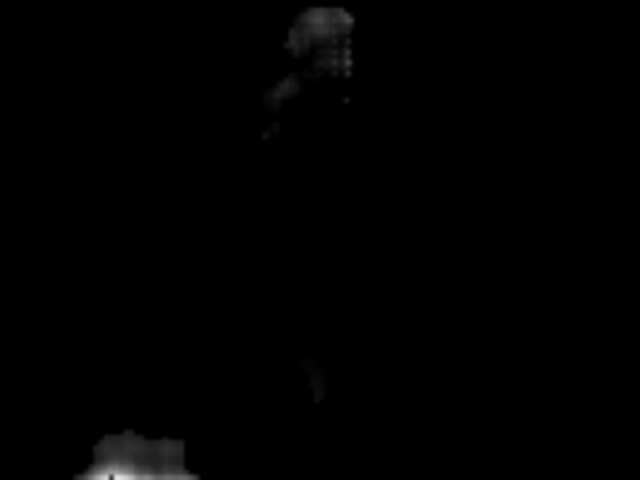

000001.png


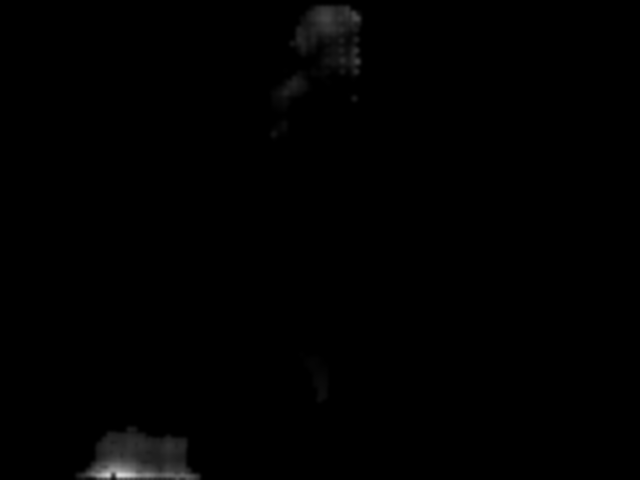

000002.png


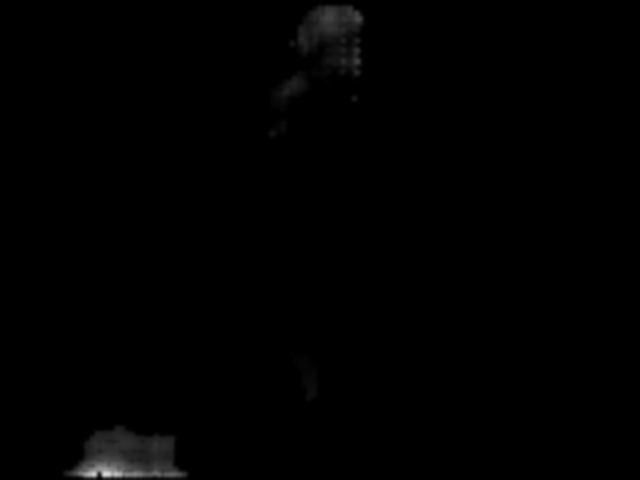


== static_weight_png ==
000000.png


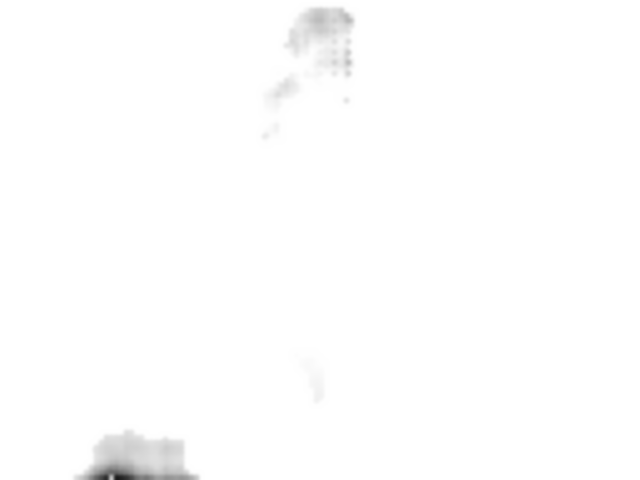

000001.png


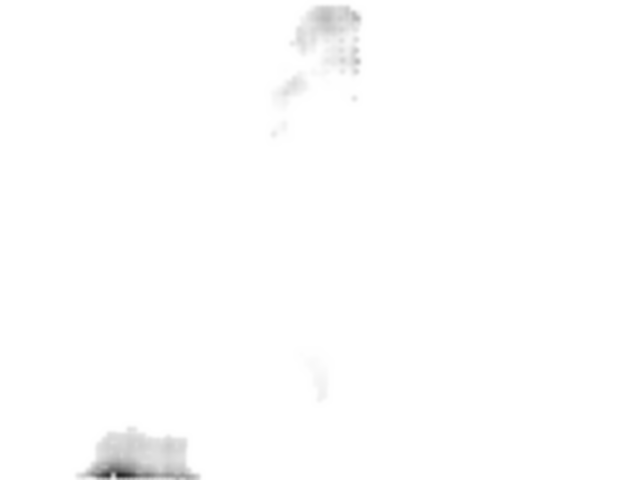

000002.png


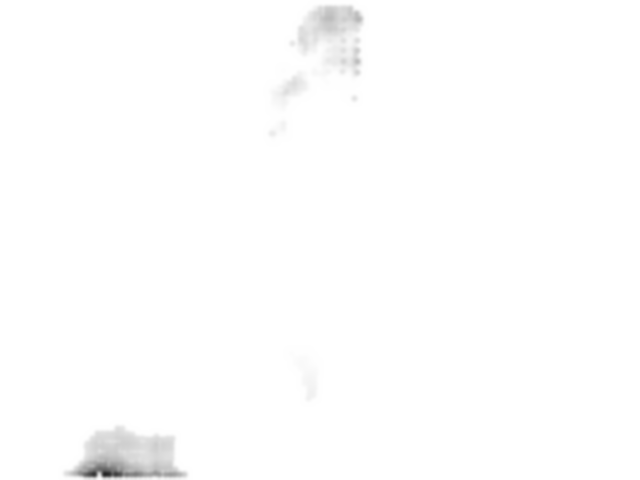


== overlay_dynamic ==
000000.png


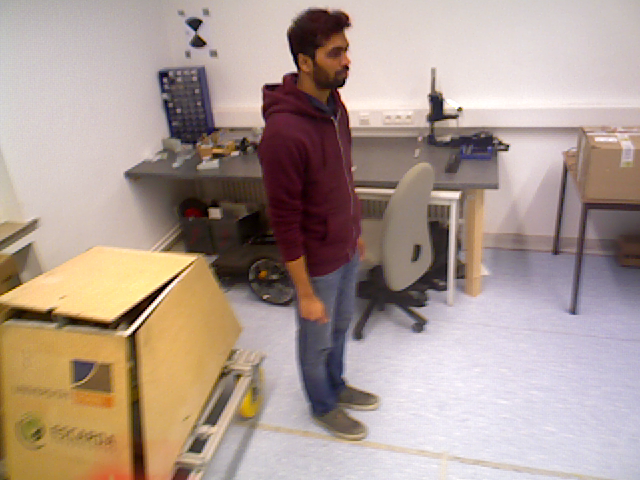

000001.png


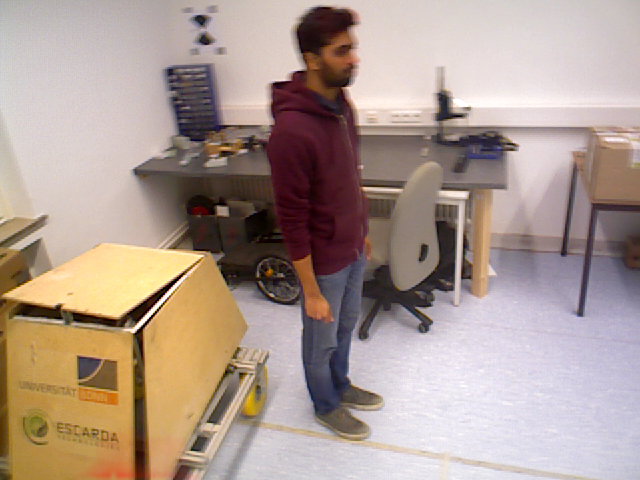

000002.png


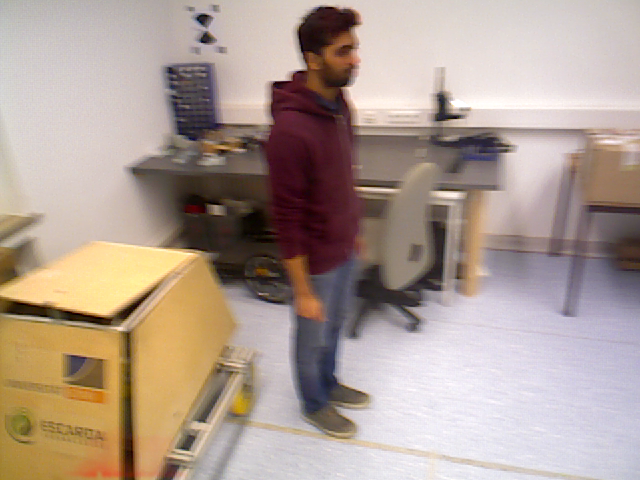

In [43]:
from pathlib import Path
from IPython.display import display
from PIL import Image
import json

out = Path(DROIDW_WEIGHT_DIR)
print("Output:", out)

summary_path = out / "summary.json"
if summary_path.exists():
    print(summary_path.read_text()[:2000])

for sub in ["dynamic_prob_png", "static_weight_png", "overlay_dynamic"]:
    print("\n==", sub, "==")
    imgs = sorted((out / sub).glob("*.png"))[:3]
    for p in imgs:
        print(p.name)
        display(Image.open(p))


## 12. Optional: run DROID-W baseline and DROID-W + Ours

Only run this section after your DROID-W code has been patched in VSCode:
1. dataloader can read `ours_dynamic.static_weight_dir`
2. `MotionFilter` passes `ours_static_weight` to `DepthVideo`
3. `DepthVideo.ba()` multiplies original BA weight by `ours_static_weight`

If not patched yet, stop at Section 11.


In [45]:
%cd /content/vggt-demo

# Make sure DROID-W exists
!git submodule update --init --recursive || true
![ -d third_party/DROID-W ] || git clone https://github.com/MoyangLi00/DROID-W.git third_party/DROID-W

%cd /content/vggt-demo/third_party/DROID-W

# Link Bonn data into DROID-W expected dataset folder
!mkdir -p Datasets
!ln -sfn "/content/drive/MyDrive/Datasets/Bonn" Datasets/Bonn

!echo "Bonn data:"
!find Datasets/Bonn -maxdepth 2 -type d | head -20

!echo "Bonn configs:"
!find configs -path "*Bonn*" -type f | sort

/content/vggt-demo
Submodule 'third_party/DROID-W' (https://github.com/MoyangLi00/DROID-W.git) registered for path 'third_party/DROID-W'
Cloning into '/content/vggt-demo/third_party/DROID-W'...
Submodule path 'third_party/DROID-W': checked out 'c3414af6047d06bafc1a6645d09f23247f3b2cdc'
Submodule 'thirdparty/diff-gaussian-rasterization-w-pose' (https://github.com/rmurai0610/diff-gaussian-rasterization-w-pose.git) registered for path 'third_party/DROID-W/thirdparty/diff-gaussian-rasterization-w-pose'
Submodule 'thirdparty/lietorch' (https://github.com/princeton-vl/lietorch.git) registered for path 'third_party/DROID-W/thirdparty/lietorch'
Submodule 'thirdparty/simple-knn' (https://github.com/camenduru/simple-knn.git) registered for path 'third_party/DROID-W/thirdparty/simple-knn'
Cloning into '/content/vggt-demo/third_party/DROID-W/thirdparty/diff-gaussian-rasterization-w-pose'...
Cloning into '/content/vggt-demo/third_party/DROID-W/thirdparty/lietorch'...
Cloning into '/content/vggt-dem

In [49]:
%%bash
%cd /content/vggt-demo/third_party/DROID-W

BASE_CFG="configs/Dynamic/Bonn/bonn_person_tracking.yaml"

if [ ! -f "$BASE_CFG" ]; then
  echo "Could not find $BASE_CFG"
  echo "Choose a Bonn config from this list:"
  find configs -path "*Bonn*" -type f | sort
else
  OURS_CFG="configs/Dynamic/Bonn/person_tracking_ours.yaml"
  cp "$BASE_CFG" "$OURS_CFG"

  cat >> "$OURS_CFG" <<EOF

ours_dynamic:
  enable: true
  static_weight_dir: /content/vggt-demo/outputs/droidw_ours_weights/person_tracking/static_weight_npy
  sequential_names: true
  alpha: 1.0
  min_weight: 0.05
EOF

  echo "Created $OURS_CFG"
  tail -20 "$OURS_CFG"
fi


Created configs/Dynamic/Bonn/person_tracking_ours.yaml
inherit_from: ./configs/Dynamic/Bonn/bonn_dynamic.yaml
scene: bonn_person_tracking

data:
  input_folder: ROOT_FOLDER_PLACEHOLDER/rgbd_bonn_person_tracking

ours_dynamic:
  enable: true
  static_weight_dir: /content/vggt-demo/outputs/droidw_ours_weights/person_tracking/static_weight_npy
  sequential_names: true
  alpha: 1.0
  min_weight: 0.05


bash: line 1: fg: no job control


In [55]:
%cd /content/vggt-demo/third_party/DROID-W

!python -m pip install -q munch
!python -m pip install -q droid_backends

!python - <<'PY'
from munch import munchify
print("munch import OK")
PY

/content/vggt-demo/third_party/DROID-W
ERROR: Could not find a version that satisfies the requirement droid_backends (from versions: none)
ERROR: No matching distribution found for droid_backends
/bin/bash: line 1: warning: here-document at line 1 delimited by end-of-file (wanted `PY')
munch import OK


NameError: name 'PY' is not defined

In [58]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Patch PyTorch 2.x dispatch API ===="

python - <<'PY'
from pathlib import Path

patches = {
    "src/lib/altcorr_kernel.cu": [
        ("fmap1.type()", "fmap1.scalar_type()"),
        ("fmap2.type()", "fmap2.scalar_type()"),
    ],
    "src/lib/correlation_kernels.cu": [
        ("volume.type()", "volume.scalar_type()"),
    ],
}

for file, reps in patches.items():
    p = Path(file)
    s = p.read_text()
    old = s
    for a, b in reps:
        s = s.replace(a, b)
    p.write_text(s)
    print(f"patched {file}: changed={s != old}")

print("Check remaining .type() in CUDA dispatch files:")
for file in ["src/lib/altcorr_kernel.cu", "src/lib/correlation_kernels.cu"]:
    p = Path(file)
    for i, line in enumerate(p.read_text().splitlines(), 1):
        if ".type()" in line:
            print(file, i, line.strip())
PY

echo "==== Clean old build ===="
rm -rf build *.egg-info
find . -name "*.so" -delete
find . -name "__pycache__" -type d -exec rm -rf {} + 2>/dev/null || true

echo "==== Install build deps ===="
python -m pip install -q ninja pybind11 munch pyyaml tqdm scipy opencv-python imageio imageio-ffmpeg matplotlib tensorboardX einops

echo "==== Build droid_backends ===="
export MAX_JOBS=1
export TORCH_CUDA_ARCH_LIST="7.5"

python setup.py build_ext --inplace -v 2>&1 | tee /content/droidw_build_log_patch.txt

echo "==== Test import ===="
PYTHONPATH=/content/vggt-demo/third_party/DROID-W:$PYTHONPATH python - <<'PY'
import droid_backends
print("droid_backends import OK")
PY

==== Patch PyTorch 2.x dispatch API ====
patched src/lib/altcorr_kernel.cu: changed=True
patched src/lib/correlation_kernels.cu: changed=True
Check remaining .type() in CUDA dispatch files:
==== Clean old build ====
==== Install build deps ====
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 314.2/314.2 kB 7.1 MB/s eta 0:00:00
==== Build droid_backends ====
running build_ext
/usr/local/lib/python3.12/dist-packages/torch/utils/cpp_extension.py:448: UserWarning: The detected CUDA version (12.8) has a minor version mismatch with the version that was used to compile PyTorch (12.4). Most likely this shouldn't be a problem.
  warnings.warn(CUDA_MISMATCH_WARN.format(cuda_str_version, torch.version.cuda))
/usr/local/lib/python3.12/dist-packages/torch/utils/cpp_extension.py:458: UserWarning: There are no x86_64-linux-gnu-g++ version bounds defined for CUDA version 12.8
  warnings.warn(f'There are no {compiler_name} version bounds defined for CUDA version {cuda_str_version}')
building 'droid_backend

Traceback (most recent call last):
  File "<stdin>", line 1, in <module>
ImportError: libc10.so: cannot open shared object file: No such file or directory


CalledProcessError: Command 'b'set -e\n\ncd /content/vggt-demo/third_party/DROID-W\n\necho "==== Patch PyTorch 2.x dispatch API ===="\n\npython - <<\'PY\'\nfrom pathlib import Path\n\npatches = {\n    "src/lib/altcorr_kernel.cu": [\n        ("fmap1.type()", "fmap1.scalar_type()"),\n        ("fmap2.type()", "fmap2.scalar_type()"),\n    ],\n    "src/lib/correlation_kernels.cu": [\n        ("volume.type()", "volume.scalar_type()"),\n    ],\n}\n\nfor file, reps in patches.items():\n    p = Path(file)\n    s = p.read_text()\n    old = s\n    for a, b in reps:\n        s = s.replace(a, b)\n    p.write_text(s)\n    print(f"patched {file}: changed={s != old}")\n\nprint("Check remaining .type() in CUDA dispatch files:")\nfor file in ["src/lib/altcorr_kernel.cu", "src/lib/correlation_kernels.cu"]:\n    p = Path(file)\n    for i, line in enumerate(p.read_text().splitlines(), 1):\n        if ".type()" in line:\n            print(file, i, line.strip())\nPY\n\necho "==== Clean old build ===="\nrm -r

In [59]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

# Find torch lib path
TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

echo "TORCH_LIB=$TORCH_LIB"

# Add torch/lib to dynamic library search path
export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"

# Add DROID-W repo to Python path
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"

echo "Check droid_backends .so:"
find . -name "droid_backends*.so" -print

echo "Test import:"
python - <<'PY'
import torch, os
print("torch:", torch.__version__)
print("torch lib:", os.path.join(os.path.dirname(torch.__file__), "lib"))

import droid_backends
print("droid_backends import OK")
PY

TORCH_LIB=/usr/local/lib/python3.12/dist-packages/torch/lib
Check droid_backends .so:
./build/lib.linux-x86_64-cpython-312/droid_backends.cpython-312-x86_64-linux-gnu.so
./droid_backends.cpython-312-x86_64-linux-gnu.so
Test import:
torch: 2.6.0+cu124
torch lib: /usr/local/lib/python3.12/dist-packages/torch/lib
droid_backends import OK


In [ ]:
# 以后用这个跑DOIRD-W
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"

python run.py configs/Dynamic/Bonn/bonn_person_tracking.yaml

In [ ]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"

python run.py configs/Dynamic/Bonn/person_tracking_ours.yaml

In [60]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"

python - <<'PY'
import droid_backends
print("droid_backends import OK")
PY

droid_backends import OK


In [63]:
%%bash
set -e

echo "==== Torch info ===="
python - <<'PY'
import torch
print("torch:", torch.__version__)
print("cuda:", torch.version.cuda)
print("cuda available:", torch.cuda.is_available())
PY

echo "==== Install torch_scatter for torch 2.6.0 + cu124 ===="
python -m pip install -q torch_scatter -f https://data.pyg.org/whl/torch-2.6.0+cu124.html

echo "==== Test imports ===="
cd /content/vggt-demo/third_party/DROID-W

TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"

python - <<'PY'
import torch
from torch_scatter import scatter_mean
import droid_backends

print("torch:", torch.__version__)
print("torch_scatter import OK")
print("droid_backends import OK")
PY

==== Torch info ====
torch: 2.6.0+cu124
cuda: 12.4
cuda available: True
==== Install torch_scatter for torch 2.6.0 + cu124 ====
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 100.8 MB/s eta 0:00:00
==== Test imports ====
torch: 2.6.0+cu124
torch_scatter import OK
droid_backends import OK


In [68]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Fix wrong scalar_type().is_cuda() in lietorch extras ===="

python - <<'PY'
from pathlib import Path

root = Path("thirdparty/lietorch/lietorch")

files = []
for ext in ["*.cpp", "*.cu", "*.h", "*.hpp"]:
    files.extend(root.rglob(ext))

changed = []
for p in files:
    s = p.read_text()
    old = s

    # Wrong from previous broad patch:
    # x.scalar_type().is_cuda()
    # Correct:
    # x.is_cuda()
    s = s.replace(".scalar_type().is_cuda()", ".is_cuda()")

    if s != old:
        p.write_text(s)
        changed.append(str(p))

print("Changed files:")
for f in changed:
    print("  ", f)

print("\nCheck remaining scalar_type().is_cuda():")
bad = False
for p in files:
    s = p.read_text()
    if ".scalar_type().is_cuda()" in s:
        print("  BAD:", p)
        bad = True

if bad:
    raise SystemExit("Still has wrong scalar_type().is_cuda()")
else:
    print("  None")
PY

echo "==== Clean lietorch old build ===="
rm -rf thirdparty/lietorch/build thirdparty/lietorch/*.egg-info
find thirdparty/lietorch -name "*.so" -delete
find thirdparty/lietorch -name "__pycache__" -type d -exec rm -rf {} + 2>/dev/null || true

echo "==== Build env ===="
TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"
export MAX_JOBS=1
export TORCH_CUDA_ARCH_LIST="7.5"

echo "TORCH_LIB=$TORCH_LIB"

echo "==== Reinstall lietorch ===="
python -m pip install -q ninja pybind11
python -m pip install -e thirdparty/lietorch --no-build-isolation -v 2>&1 | tee /content/lietorch_build_log_fix_is_cuda.txt

echo "==== Test imports ===="
python - <<'PY'
import torch
import lietorch
import droid_backends
from torch_scatter import scatter_mean

print("torch:", torch.__version__)
print("lietorch import OK")
print("droid_backends import OK")
print("torch_scatter import OK")
PY

==== Fix wrong scalar_type().is_cuda() in lietorch extras ====
Changed files:
   thirdparty/lietorch/lietorch/extras/extras.cpp

Check remaining scalar_type().is_cuda():
  None
==== Clean lietorch old build ====
==== Build env ====
TORCH_LIB=/usr/local/lib/python3.12/dist-packages/torch/lib
==== Reinstall lietorch ====
Using pip 24.1.2 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)
Obtaining file:///content/vggt-demo/third_party/DROID-W/thirdparty/lietorch
  Preparing metadata (setup.py): started
  Running command python setup.py egg_info
  running egg_info
  creating /tmp/pip-pip-egg-info-n8xb2f82/lietorch.egg-info
  writing /tmp/pip-pip-egg-info-n8xb2f82/lietorch.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-pip-egg-info-n8xb2f82/lietorch.egg-info/dependency_links.txt
  writing top-level names to /tmp/pip-pip-egg-info-n8xb2f82/lietorch.egg-info/top_level.txt
  writing manifest file '/tmp/pip-pip-egg-info-n8xb2f82/lietorch.egg-info/SOURCES.txt'
  reading man

In [70]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Install missing Python deps ===="
python -m pip install -q colorama natsort yacs gdown open3d evo

echo "==== Test basic imports ===="
TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"

python - <<'PY'
import colorama
import torch
import droid_backends
import lietorch
from torch_scatter import scatter_mean

print("colorama OK")
print("droid_backends OK")
print("lietorch OK")
print("torch_scatter OK")
print("torch:", torch.__version__)
PY

==== Install missing Python deps ====
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.7/447.7 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.2/162.2 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 121.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.8/139.8 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.8/144.8 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.6/42.6 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 222.6/222.6 kB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 104.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 62.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 133.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.7/61.7 kB 6.7 MB/s eta 0:00:00
==== Test 

In [72]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Prepare env ===="
TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"
export MAX_JOBS=1
export TORCH_CUDA_ARCH_LIST="7.5"

echo "TORCH_LIB=$TORCH_LIB"

echo "==== Update submodules ===="
git submodule update --init --recursive || true

echo "==== Check gaussian rasterizer folders ===="
find thirdparty -maxdepth 3 -type d | grep -Ei "gaussian|raster|knn" || true
find thirdparty -maxdepth 4 -name "setup.py" | sort

echo "==== Install diff gaussian rasterization ===="

if [ -d thirdparty/diff-gaussian-rasterization-w-pose ]; then
  python -m pip install -e thirdparty/diff-gaussian-rasterization-w-pose --no-build-isolation -v
elif [ -d thirdparty/diff-gaussian-rasterization ]; then
  python -m pip install -e thirdparty/diff-gaussian-rasterization --no-build-isolation -v
elif [ -d thirdparty/gaussian_splatting/submodules/diff-gaussian-rasterization ]; then
  python -m pip install -e thirdparty/gaussian_splatting/submodules/diff-gaussian-rasterization --no-build-isolation -v
else
  echo "Cannot find diff gaussian rasterization folder."
  echo "Available setup.py files:"
  find thirdparty -maxdepth 5 -name "setup.py" | sort
  exit 1
fi

echo "==== Install simple-knn if exists ===="
if [ -d thirdparty/simple-knn ]; then
  python -m pip install -e thirdparty/simple-knn --no-build-isolation -v || true
elif [ -d thirdparty/gaussian_splatting/submodules/simple-knn ]; then
  python -m pip install -e thirdparty/gaussian_splatting/submodules/simple-knn --no-build-isolation -v || true
fi

echo "==== Test imports ===="
python - <<'PY'
import torch
import droid_backends
import lietorch
from torch_scatter import scatter_mean
import diff_gaussian_rasterization

print("torch:", torch.__version__)
print("droid_backends OK")
print("lietorch OK")
print("torch_scatter OK")
print("diff_gaussian_rasterization OK")
PY

==== Prepare env ====
TORCH_LIB=/usr/local/lib/python3.12/dist-packages/torch/lib
==== Update submodules ====
==== Check gaussian rasterizer folders ====
thirdparty/gaussian_splatting
thirdparty/gaussian_splatting/scene
thirdparty/gaussian_splatting/gaussian_renderer
thirdparty/gaussian_splatting/gaussian_renderer/__pycache__
thirdparty/gaussian_splatting/__pycache__
thirdparty/gaussian_splatting/utils
thirdparty/gaussian_splatting/utils/__pycache__
thirdparty/diff-gaussian-rasterization-w-pose
thirdparty/diff-gaussian-rasterization-w-pose/diff_gaussian_rasterization
thirdparty/diff-gaussian-rasterization-w-pose/cuda_rasterizer
thirdparty/diff-gaussian-rasterization-w-pose/third_party
thirdparty/diff-gaussian-rasterization-w-pose/third_party/glm
thirdparty/simple-knn
thirdparty/simple-knn/simple_knn
thirdparty/diff-gaussian-rasterization-w-pose/setup.py
thirdparty/lietorch/setup.py
thirdparty/simple-knn/setup.py
==== Install diff gaussian rasterization ====
Using pip 24.1.2 from /usr/l

  Running command python setup.py egg_info
  running egg_info
  creating /tmp/pip-pip-egg-info-895j4hlj/diff_gaussian_rasterization.egg-info
  writing /tmp/pip-pip-egg-info-895j4hlj/diff_gaussian_rasterization.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-pip-egg-info-895j4hlj/diff_gaussian_rasterization.egg-info/dependency_links.txt
  writing top-level names to /tmp/pip-pip-egg-info-895j4hlj/diff_gaussian_rasterization.egg-info/top_level.txt
  writing manifest file '/tmp/pip-pip-egg-info-895j4hlj/diff_gaussian_rasterization.egg-info/SOURCES.txt'
  reading manifest file '/tmp/pip-pip-egg-info-895j4hlj/diff_gaussian_rasterization.egg-info/SOURCES.txt'
  adding license file 'LICENSE.md'
  writing manifest file '/tmp/pip-pip-egg-info-895j4hlj/diff_gaussian_rasterization.egg-info/SOURCES.txt'
    Running command python setup.py develop
    running develop
    /usr/local/lib/python3.12/dist-packages/setuptools/command/develop.py:41: EasyInstallDeprecationWarning: easy_install com

In [75]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Patch simple-knn FLT_MAX include ===="

python - <<'PY'
from pathlib import Path

p = Path("thirdparty/simple-knn/simple_knn.cu")
s = p.read_text()

if "#include <cfloat>" not in s and "#include <float.h>" not in s:
    lines = s.splitlines()

    # Put include near the top, after existing includes if possible
    insert_idx = 0
    for i, line in enumerate(lines):
        if line.strip().startswith("#include"):
            insert_idx = i + 1

    lines.insert(insert_idx, "#include <cfloat>")
    s = "\n".join(lines) + "\n"
    p.write_text(s)
    print("Added #include <cfloat> to", p)
else:
    print("cfloat / float.h already exists in", p)

print("Check FLT_MAX:")
for i, line in enumerate(p.read_text().splitlines(), 1):
    if "FLT_MAX" in line or "cfloat" in line or "float.h" in line:
        print(i, line)
PY

echo "==== Clean simple-knn old build ===="
rm -rf thirdparty/simple-knn/build thirdparty/simple-knn/*.egg-info
find thirdparty/simple-knn -name "*.so" -delete
find thirdparty/simple-knn -name "__pycache__" -type d -exec rm -rf {} + 2>/dev/null || true

echo "==== Prepare env ===="
TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"
export MAX_JOBS=1
export TORCH_CUDA_ARCH_LIST="7.5"

echo "TORCH_LIB=$TORCH_LIB"

echo "==== Reinstall simple-knn ===="
python -m pip install -e thirdparty/simple-knn --no-build-isolation -v

echo "==== Test imports ===="
python - <<'PY'
import torch
import droid_backends
import lietorch
import diff_gaussian_rasterization
from simple_knn._C import distCUDA2

print("torch:", torch.__version__)
print("droid_backends OK")
print("lietorch OK")
print("diff_gaussian_rasterization OK")
print("simple_knn OK")
PY

==== Patch simple-knn FLT_MAX include ====
Added #include <cfloat> to thirdparty/simple-knn/simple_knn.cu
Check FLT_MAX:
26 #include <cfloat>
91 		me.minn = { FLT_MAX, FLT_MAX, FLT_MAX };
92 		me.maxx = { -FLT_MAX,-FLT_MAX,-FLT_MAX };
155 	float best[3] = { FLT_MAX, FLT_MAX, FLT_MAX };
165 	best[0] = FLT_MAX;
166 	best[1] = FLT_MAX;
167 	best[2] = FLT_MAX;
==== Clean simple-knn old build ====
==== Prepare env ====
TORCH_LIB=/usr/local/lib/python3.12/dist-packages/torch/lib
==== Reinstall simple-knn ====
Using pip 24.1.2 from /usr/local/lib/python3.12/dist-packages/pip (python 3.12)
Obtaining file:///content/vggt-demo/third_party/DROID-W/thirdparty/simple-knn
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Running setup.py develop for simple_knn
==== Test imports ====
torch: 2.6.0+cu124
droid_backends OK
lietorch OK
diff_gaussian_rasterization OK
simple_knn OK


  Running command python setup.py egg_info
  running egg_info
  creating /tmp/pip-pip-egg-info-af7tcd_l/simple_knn.egg-info
  writing /tmp/pip-pip-egg-info-af7tcd_l/simple_knn.egg-info/PKG-INFO
  writing dependency_links to /tmp/pip-pip-egg-info-af7tcd_l/simple_knn.egg-info/dependency_links.txt
  writing top-level names to /tmp/pip-pip-egg-info-af7tcd_l/simple_knn.egg-info/top_level.txt
  writing manifest file '/tmp/pip-pip-egg-info-af7tcd_l/simple_knn.egg-info/SOURCES.txt'
  reading manifest file '/tmp/pip-pip-egg-info-af7tcd_l/simple_knn.egg-info/SOURCES.txt'
  writing manifest file '/tmp/pip-pip-egg-info-af7tcd_l/simple_knn.egg-info/SOURCES.txt'
    Running command python setup.py develop
    running develop
    /usr/local/lib/python3.12/dist-packages/setuptools/command/develop.py:41: EasyInstallDeprecationWarning: easy_install command is deprecated.
    !!

            ********************************************************************************
            Please avoid running 

In [77]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Install GUI-related Python deps ===="
python -m pip install -q glfw PyOpenGL PyOpenGL-accelerate imgui

echo "==== Test imports ===="
TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"

python - <<'PY'
import glfw
import OpenGL
import imgui

import torch
import droid_backends
import lietorch
import diff_gaussian_rasterization
from simple_knn._C import distCUDA2
from torch_scatter import scatter_mean

print("glfw OK")
print("OpenGL OK")
print("imgui OK")
print("droid_backends OK")
print("lietorch OK")
print("diff_gaussian_rasterization OK")
print("simple_knn OK")
print("torch_scatter OK")
print("torch:", torch.__version__)
PY

==== Install GUI-related Python deps ====
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 19.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 90.7 MB/s eta 0:00:00
==== Test imports ====
glfw OK
OpenGL OK
imgui OK
droid_backends OK
lietorch OK
diff_gaussian_rasterization OK
simple_knn OK
torch_scatter OK
torch: 2.6.0+cu124


In [79]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Install missing imgviz ===="
python -m pip install -q imgviz

echo "==== Test imports ===="
TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"

python - <<'PY'
import imgviz
import glfw
import OpenGL
import imgui

import torch
import droid_backends
import lietorch
import diff_gaussian_rasterization
from simple_knn._C import distCUDA2
from torch_scatter import scatter_mean

print("imgviz OK")
print("glfw OK")
print("OpenGL OK")
print("imgui OK")
print("droid_backends OK")
print("lietorch OK")
print("diff_gaussian_rasterization OK")
print("simple_knn OK")
print("torch_scatter OK")
print("torch:", torch.__version__)
PY

==== Install missing imgviz ====
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 59.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 995.9/995.9 kB 52.7 MB/s eta 0:00:00
==== Test imports ====
imgviz OK
glfw OK
OpenGL OK
imgui OK
droid_backends OK
lietorch OK
diff_gaussian_rasterization OK
simple_knn OK
torch_scatter OK
torch: 2.6.0+cu124


In [81]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Install glm / GUI dependencies ===="
python -m pip install -q PyGLM glfw PyOpenGL PyOpenGL-accelerate imgui imgviz

echo "==== Test imports ===="
TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"

python - <<'PY'
import glm
import glfw
import OpenGL
import imgui
import imgviz

import torch
import droid_backends
import lietorch
import diff_gaussian_rasterization
from simple_knn._C import distCUDA2
from torch_scatter import scatter_mean

print("glm OK")
print("GUI deps OK")
print("droid_backends OK")
print("lietorch OK")
print("diff_gaussian_rasterization OK")
print("simple_knn OK")
print("torch_scatter OK")
print("torch:", torch.__version__)
PY

==== Install glm / GUI dependencies ====
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 97.5 MB/s eta 0:00:00
==== Test imports ====
glm OK
GUI deps OK
droid_backends OK
lietorch OK
diff_gaussian_rasterization OK
simple_knn OK
torch_scatter OK
torch: 2.6.0+cu124


In [84]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Patch NumPy 2.x np.unicode_ issue ===="

python - <<'PY'
from pathlib import Path

files = [
    Path("src/utils/datasets.py"),
]

for p in files:
    s = p.read_text()
    old = s
    s = s.replace("np.unicode_", "np.str_")
    p.write_text(s)
    print(f"patched {p}: changed={s != old}")

print("\nCheck remaining np.unicode_:")
for p in Path(".").rglob("*.py"):
    s = p.read_text(errors="ignore")
    if "np.unicode_" in s:
        print("still exists:", p)
PY

==== Patch NumPy 2.x np.unicode_ issue ====
patched src/utils/datasets.py: changed=True

Check remaining np.unicode_:
still exists: thirdparty/lietorch/examples/core/data_readers/rgbd_utils.py


In [86]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Check config path ===="
grep -n "rgbd_bonn\|datasets\|input\|base_dir\|datapath" configs/Dynamic/Bonn/bonn_person_tracking.yaml || true

echo "==== Create expected dataset link ===="

mkdir -p datasets/Bonn

# Find your actual Bonn sequence folder
if [ -d "/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking" ]; then
  SRC="/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking"
elif [ -d "/content/drive/MyDrive/Datasets/Bonn/person_tracking" ]; then
  SRC="/content/drive/MyDrive/Datasets/Bonn/person_tracking"
else
  echo "Could not find default Bonn folder. Searching..."
  SRC=$(find /content/drive/MyDrive/Datasets/Bonn -maxdepth 3 -type d | grep -Ei "person.*tracking|rgbd_bonn_person_tracking" | head -1)
fi

echo "SRC=$SRC"

if [ -z "$SRC" ] || [ ! -d "$SRC" ]; then
  echo "ERROR: Cannot find Bonn person_tracking sequence folder."
  echo "Available folders:"
  find /content/drive/MyDrive/Datasets/Bonn -maxdepth 3 -type d | head -80
  exit 1
fi

# DROID-W expects this exact path:
ln -sfn "$SRC" datasets/Bonn/rgbd_bonn_person_tracking

echo "Linked:"
ls -lah datasets/Bonn
ls -lah datasets/Bonn/rgbd_bonn_person_tracking | head -40

echo "==== Check required files ===="
SEQ="datasets/Bonn/rgbd_bonn_person_tracking"

echo "rgb.txt:"
ls -lah "$SEQ/rgb.txt" || true

echo "depth.txt:"
ls -lah "$SEQ/depth.txt" || true

echo "groundtruth.txt:"
ls -lah "$SEQ/groundtruth.txt" || true

echo "rgb folder:"
ls -lah "$SEQ/rgb" | head || true

echo "depth folder:"
ls -lah "$SEQ/depth" | head || true

==== Check config path ====
5:  input_folder: ROOT_FOLDER_PLACEHOLDER/rgbd_bonn_person_tracking
==== Create expected dataset link ====
SRC=/content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking
Linked:
total 12K
drwxr-xr-x 2 root root 4.0K Jul  2 22:07 .
drwxr-xr-x 3 root root 4.0K Jul  2 22:07 ..
lrwxrwxrwx 1 root root   62 Jul  2 22:07 rgbd_bonn_person_tracking -> /content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking
lrwxrwxrwx 1 root root 62 Jul  2 22:07 datasets/Bonn/rgbd_bonn_person_tracking -> /content/drive/MyDrive/Datasets/Bonn/rgbd_bonn_person_tracking
==== Check required files ====
rgb.txt:
-rw------- 1 root root 24K Jan 29  2019 datasets/Bonn/rgbd_bonn_person_tracking/rgb.txt
depth.txt:
-rw------- 1 root root 26K Jan 29  2019 datasets/Bonn/rgbd_bonn_person_tracking/depth.txt
groundtruth.txt:
-rw------- 1 root root 48K Jan 29  2019 datasets/Bonn/rgbd_bonn_person_tracking/groundtruth.txt
rgb folder:
total 253M
-rw------- 1 root root 465K Jan 29  2019 154826588

In [89]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Make pretrained folder ===="
mkdir -p pretrained

echo "==== Check existing pretrained files ===="
ls -lah pretrained || true

echo "==== Try download droid.pth ===="

# Option A: HuggingFace mirror
if [ ! -f pretrained/droid.pth ]; then
  wget -O pretrained/droid.pth \
    https://huggingface.co/vslamlab/droidslam/resolve/main/droid.pth
fi

echo "==== Check downloaded file ===="
ls -lh pretrained/droid.pth

python - <<'PY'
from pathlib import Path
p = Path("pretrained/droid.pth")
print("exists:", p.exists())
print("size MB:", p.stat().st_size / 1024 / 1024 if p.exists() else None)
assert p.exists() and p.stat().st_size > 10_000_000, "droid.pth download seems failed or too small"
PY

==== Make pretrained folder ====
==== Check existing pretrained files ====
total 8.0K
drwxr-xr-x  2 root root 4.0K Jul  2 22:10 .
drwxr-xr-x 14 root root 4.0K Jul  2 22:10 ..
==== Try download droid.pth ====
==== Check downloaded file ====
-rw-r--r-- 1 root root 16M Jul  2 22:10 pretrained/droid.pth
exists: True
size MB: 15.317631721496582


--2026-07-02 22:10:28--  https://huggingface.co/vslamlab/droidslam/resolve/main/droid.pth
Resolving huggingface.co (huggingface.co)... 3.166.152.44, 3.166.152.65, 3.166.152.110, ...
Connecting to huggingface.co (huggingface.co)|3.166.152.44|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.aws.cdn.hf.co/xet-bridge-us/68199ce01a1d2d7631ad5232/8fc5a8a9fd34028b33b36220252c138fe8cfc717743da06a7fc4939917d29e72?response-content-disposition=inline%3B+filename*%3DUTF-8%27%27droid.pth%3B+filename%3D%22droid.pth%22%3B&user_id=public&X-Xet-Cas-Uid=public&Expires=1783033828&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5hd3MuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjgxOTljZTAxYTFkMmQ3NjMxYWQ1MjMyLzhmYzVhOGE5ZmQzNDAyOGIzM2IzNjIyMDI1MmMxMzhmZThjZmM3MTc3NDNkYTA2YTdmYzQ5Mzk5MTdkMjllNzJcXD9yZXNwb25zZS1jb250ZW50LWRpc3Bvc2l0aW9uPWlubGluZSUzQitmaWxlbmFtZSUyQSUzRFVURi04JTI3JTI3ZHJvaWQucHRoJTNCK2ZpbGVuYW1lJTNEJTIyZHJvaWQucHRoJTIyJTNCJnVzZXJfaWQ9cHVibGljJlgtWGV0LUNh

In [91]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Install Metric3D dependencies ===="
python -m pip install -q mmengine mmcv-lite timm addict yapf

echo "==== Test Metric3D imports ===="
python - <<'PY'
from mmengine import Config, DictAction
import timm
print("mmengine OK")
print("timm OK")
PY

==== Install Metric3D dependencies ====
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 452.7/452.7 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 732.3/732.3 kB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 5.8 MB/s eta 0:00:00
==== Test Metric3D imports ====
mmengine OK
timm OK


In [95]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Patch DINO / FiT3D feature reshape ===="

python - <<'PY'
from pathlib import Path

p = Path("src/utils/mono_priors/img_feature_extractors.py")
s = p.read_text()

bak = p.with_suffix(".py.bak_fix_feature_reshape")
if not bak.exists():
    bak.write_text(s)

old_block = """if hasattr(self.model, "_intermediate_layers"):
            outputs = self.model._intermediate_layers(x, n)
        else:
            outputs = self.model.get_intermediate_layers(x, n=n)"""

new_block = """if hasattr(self.model, "_intermediate_layers"):
            outputs = self.model._intermediate_layers(x, n)
        else:
            # Newer DINO / FiT3D API.
            # Return spatial feature maps directly to avoid token-grid mismatch.
            outputs = self.model.get_intermediate_layers(
                x,
                n=n,
                reshape=True,
                return_class_token=False,
            )"""

if old_block in s:
    s = s.replace(old_block, new_block)
else:
    print("Old block not found. Showing related lines:")
    for i, line in enumerate(s.splitlines(), 1):
        if "_intermediate_layers" in line or "get_intermediate_layers" in line or "reshape" in line:
            print(i, line)
    raise SystemExit("Patch target not found")

# Now patch the later reshape part to skip reshape if output is already BCHW.
old_reshape = """features = [
            out.reshape(x.shape[0], grid_size[0], grid_size[1], -1)
            .permute(0, 3, 1, 2)
            .contiguous()
            for out in outputs
        ]"""

new_reshape = """features = []
        for out in outputs:
            # New API with reshape=True already returns B,C,H,W.
            if out.ndim == 4:
                features.append(out.contiguous())
            else:
                features.append(
                    out.reshape(x.shape[0], grid_size[0], grid_size[1], -1)
                    .permute(0, 3, 1, 2)
                    .contiguous()
                )"""

if old_reshape in s:
    s = s.replace(old_reshape, new_reshape)
else:
    print("Exact reshape block not found. This may be okay if file has different formatting.")
    print("Please check related lines:")
    for i, line in enumerate(s.splitlines(), 1):
        if "reshape" in line or "permute" in line or "grid_size" in line:
            print(i, line)

p.write_text(s)

print("Patched:", p)
print("Check key lines:")
for i, line in enumerate(p.read_text().splitlines(), 1):
    if "get_intermediate_layers" in line or "reshape=True" in line or "out.ndim == 4" in line:
        print(i, line)
PY

==== Patch DINO / FiT3D feature reshape ====
Exact reshape block not found. This may be okay if file has different formatting.
Please check related lines:
25         reshape: bool = False,
38                 reshape=True,
51         if reshape:
53             grid_size = (
62                 out.reshape(x.shape[0], grid_size[0], grid_size[1], -1)
63                 .permute(0, 3, 1, 2)
141             reshape=True,
146         features = features[-1].squeeze().permute((1, 2, 0))
Patched: src/utils/mono_priors/img_feature_extractors.py
Check key lines:
11 From FiT3D, here we subclass the model instead of overriding the "get_intermediate_layers" method
21     def get_intermediate_layers(
35             outputs = self.model.get_intermediate_layers(
38                 reshape=True,
74 Done with overwriting get_intermediate_layers of FiT3D model
138         features = model.get_intermediate_layers(
141             reshape=True,


In [97]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Patch return_class_token unsupported issue ===="

python - <<'PY'
from pathlib import Path

p = Path("src/utils/mono_priors/img_feature_extractors.py")
s = p.read_text()
old = s

# Some FiT3D/timm VisionTransformer versions do not support return_class_token
lines = []
for line in s.splitlines():
    if "return_class_token" in line:
        print("Removed line:", line)
        continue
    lines.append(line)

s = "\n".join(lines) + "\n"

# Make feature handling robust if model returns tuple/list
target = "            if out.ndim == 4:\n"
replacement = """            if isinstance(out, (tuple, list)):
                out = out[0]
            if out.ndim == 4:
"""

if target in s and "if isinstance(out, (tuple, list)):" not in s:
    s = s.replace(target, replacement)

p.write_text(s)

print(f"patched {p}: changed={s != old}")

print("\nCheck related lines:")
for i, line in enumerate(p.read_text().splitlines(), 1):
    if "get_intermediate_layers" in line or "reshape=True" in line or "return_class_token" in line or "out.ndim" in line or "tuple" in line:
        print(i, line)
PY

==== Patch return_class_token unsupported issue ====
Removed line:         return_class_token: bool = False,
Removed line:                 return_class_token=False,
Removed line:         if return_class_token:
Removed line:         if return_prefix_tokens or return_class_token:
Removed line:             return_class_token=False,
patched src/utils/mono_priors/img_feature_extractors.py: changed=True

Check related lines:
11 From FiT3D, here we subclass the model instead of overriding the "get_intermediate_layers" method
21     def get_intermediate_layers(
34             outputs = self.model.get_intermediate_layers(
37                 reshape=True,
65             return tuple(zip(outputs, prefix_tokens))
66         return tuple(outputs)
70 Done with overwriting get_intermediate_layers of FiT3D model
134         features = model.get_intermediate_layers(
137             reshape=True,


In [99]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Patch DINO norm for BCHW feature maps ===="

python - <<'PY'
from pathlib import Path

p = Path("src/utils/mono_priors/img_feature_extractors.py")
s = p.read_text()

bak = p.with_suffix(".py.bak_norm_bchw")
if not bak.exists():
    bak.write_text(s)

old = "outputs = [self.model.norm(out) for out in outputs]"

new = """normed_outputs = []
        for out in outputs:
            if isinstance(out, (tuple, list)):
                out = out[0]

            # If output is already B,C,H,W, LayerNorm must be applied on channel-last.
            if out.ndim == 4:
                out = self.model.norm(
                    out.permute(0, 2, 3, 1)
                ).permute(0, 3, 1, 2).contiguous()
            else:
                out = self.model.norm(out)

            normed_outputs.append(out)

        outputs = normed_outputs"""

if old not in s:
    print("Target line not found. Showing related lines:")
    for i, line in enumerate(s.splitlines(), 1):
        if "self.model.norm" in line or "normed_outputs" in line or "get_intermediate_layers" in line:
            print(i, line)
    raise SystemExit("Patch target not found")

s = s.replace(old, new)
p.write_text(s)

print("Patched:", p)
print("\nCheck patched lines:")
for i, line in enumerate(p.read_text().splitlines(), 1):
    if "normed_outputs" in line or "self.model.norm" in line or "permute" in line:
        print(i, line)
PY

==== Patch DINO norm for BCHW feature maps ====
Patched: src/utils/mono_priors/img_feature_extractors.py

Check patched lines:
40             normed_outputs = []
47                 out = self.model.norm(
48                     out.permute(0, 2, 3, 1)
49                 ).permute(0, 3, 1, 2).contiguous()
51                 out = self.model.norm(out)
53             normed_outputs.append(out)
55         outputs = normed_outputs
75                 .permute(0, 3, 1, 2)
156         features = features[-1].squeeze().permute((1, 2, 0))


In [102]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Repair broken img_feature_extractors.py indentation ===="

python - <<'PY'
from pathlib import Path
import py_compile

p = Path("src/utils/mono_priors/img_feature_extractors.py")
s = p.read_text()

# backup current broken file
bak = p.with_suffix(".py.bak_broken_indent_fixed")
bak.write_text(s)

lines = s.splitlines()

# Find method: def get_intermediate_layers(...)
start = None
for i, line in enumerate(lines):
    if line.startswith("    def get_intermediate_layers"):
        start = i
        break

if start is None:
    raise RuntimeError("Cannot find method: def get_intermediate_layers")

# Find next method in the same class, or next top-level function
end = None
for j in range(start + 1, len(lines)):
    if lines[j].startswith("    def ") and j > start:
        end = j
        break
    if lines[j].startswith("def predict_img_features"):
        end = j
        break
    if lines[j].startswith("def get_feature_extractor"):
        end = j
        break

if end is None:
    raise RuntimeError("Cannot determine end of get_intermediate_layers")

new_func = r'''    def get_intermediate_layers(self, x, n=1):
        """
        Robust wrapper for old/new DINO / FiT3D APIs.

        It supports:
        1. Old API: self.model._intermediate_layers(x, n)
        2. New API: self.model.get_intermediate_layers(x, n=n, reshape=True)
        3. Token output: B, N, C
        4. Spatial output: B, C, H, W
        """

        outputs = None

        # Prefer public API if available
        if hasattr(self.model, "get_intermediate_layers"):
            try:
                outputs = self.model.get_intermediate_layers(
                    x,
                    n=n,
                    reshape=True,
                )
            except TypeError:
                try:
                    outputs = self.model.get_intermediate_layers(x, n=n)
                except TypeError:
                    outputs = self.model.get_intermediate_layers(x, n)

        # Fallback to old private API
        if outputs is None and hasattr(self.model, "_intermediate_layers"):
            outputs = self.model._intermediate_layers(x, n)

        if outputs is None:
            raise RuntimeError("No compatible intermediate layer API found.")

        if not isinstance(outputs, (list, tuple)):
            outputs = [outputs]

        features = []

        for out in outputs:
            if isinstance(out, (list, tuple)):
                out = out[0]

            # Case 1: already spatial feature map B,C,H,W
            if out.ndim == 4:
                # If model.norm exists, LayerNorm expects channel-last: B,H,W,C
                if hasattr(self.model, "norm"):
                    try:
                        out = self.model.norm(
                            out.permute(0, 2, 3, 1)
                        ).permute(0, 3, 1, 2).contiguous()
                    except Exception:
                        out = out.contiguous()
                else:
                    out = out.contiguous()

                features.append(out)
                continue

            # Case 2: token sequence B,N,C
            if out.ndim == 3:
                if hasattr(self.model, "norm"):
                    try:
                        out = self.model.norm(out)
                    except Exception:
                        pass

                B = x.shape[0]

                patch_size = getattr(self, "patch_size", 14)
                if isinstance(patch_size, (tuple, list)):
                    patch_size = patch_size[0]

                gh = x.shape[2] // patch_size
                gw = x.shape[3] // patch_size
                need_tokens = gh * gw

                # Remove cls/register tokens if present
                if out.shape[1] > need_tokens:
                    out = out[:, -need_tokens:, :]

                if out.shape[1] != need_tokens:
                    raise RuntimeError(
                        f"Cannot reshape DINO tokens: got {out.shape[1]} tokens, "
                        f"expected {need_tokens} = {gh}x{gw}."
                    )

                out = (
                    out.reshape(B, gh, gw, -1)
                    .permute(0, 3, 1, 2)
                    .contiguous()
                )

                features.append(out)
                continue

            raise RuntimeError(f"Unsupported DINO output shape: {tuple(out.shape)}")

        return features
'''

new_lines = lines[:start] + new_func.splitlines() + lines[end:]
p.write_text("\n".join(new_lines) + "\n")

print("Rewrote get_intermediate_layers in:", p)

print("==== Syntax check ====")
py_compile.compile(str(p), doraise=True)
print("Syntax OK")

print("==== Show patched related lines ====")
for i, line in enumerate(p.read_text().splitlines(), 1):
    if i <= 130 and (
        "def get_intermediate_layers" in line
        or "get_intermediate_layers" in line
        or "features.append" in line
        or "return features" in line
        or "reshape=True" in line
    ):
        print(f"{i}: {line}")
PY

==== Repair broken img_feature_extractors.py indentation ====
Rewrote get_intermediate_layers in: src/utils/mono_priors/img_feature_extractors.py
==== Syntax check ====
Syntax OK
==== Show patched related lines ====
11: From FiT3D, here we subclass the model instead of overriding the "get_intermediate_layers" method
21:     def get_intermediate_layers(self, x, n=1):
27:         2. New API: self.model.get_intermediate_layers(x, n=n, reshape=True)
35:         if hasattr(self.model, "get_intermediate_layers"):
37:                 outputs = self.model.get_intermediate_layers(
40:                     reshape=True,
44:                     outputs = self.model.get_intermediate_layers(x, n=n)
46:                     outputs = self.model.get_intermediate_layers(x, n)
77:                 features.append(out)
114:                 features.append(out)
119:         return features


In [105]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

echo "==== Patch Fit3DModels.get_intermediate_layers signature ===="

python - <<'PY'
from pathlib import Path
import py_compile

p = Path("src/utils/mono_priors/img_feature_extractors.py")
s = p.read_text()
old = s

# Make wrapper accept extra keyword arguments such as reshape=True
s = s.replace(
    "def get_intermediate_layers(self, x, n=1):",
    "def get_intermediate_layers(self, x, n=1, reshape=None, **kwargs):"
)

p.write_text(s)

print(f"patched {p}: changed={s != old}")

print("==== Syntax check ====")
py_compile.compile(str(p), doraise=True)
print("Syntax OK")

print("==== Check function signature ====")
for i, line in enumerate(p.read_text().splitlines(), 1):
    if "def get_intermediate_layers" in line:
        print(i, line)
PY

==== Patch Fit3DModels.get_intermediate_layers signature ====
patched src/utils/mono_priors/img_feature_extractors.py: changed=True
==== Syntax check ====
Syntax OK
==== Check function signature ====
21     def get_intermediate_layers(self, x, n=1, reshape=None, **kwargs):


In [106]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"

python run.py --config configs/Dynamic/Bonn/bonn_person_tracking.yaml

------------------------------
Start WildGS-SLAM at 2026-07-02 22:32:57,
   scene: bonn_dynamic-bonn_person_tracking,
   output: ./Outputs/Bonn/bonn_person_tracking
------------------------------
INFO: GT poses saved to ./Outputs/Bonn/bonn_person_tracking/gt_poses.txt
[INFO] Load droid pretrained checkpoint from ./pretrained/droid.pth!
[TRACKER] Tracking Triggered!
Initialized new /root/.evo/settings.json
[Timer] Summary (auto) – per decorated function:
  - Tracking: count=580, total=220.798508s, avg=0.380687s, min=0.009176s, max=3.496498s, fps=2.63
  - Metric Depth Estimation: count=129, total=131.414180s, avg=1.018715s, min=0.898431s, max=1.128905s, fps=0.98
  - Full Trajectory Filling: count=1, total=46.883860s, avg=46.883860s, min=46.883860s, max=46.883860s, fps=0.02
  - Final Global BA: count=1, total=44.642282s, avg=44.642282s, min=44.642282s, max=44.642282s, fps=0.02
  - DINO Feature Extraction: count=129, total=14.666897s, avg=0.113697s, min=0.104080s, max=0.122284s, fps=8.80
[

xFormers not available
xFormers not available
2026-07-02 22:32:53.244885: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
xFormers not available
xFormers not available
xFormers not available
xFormers not available
Using cache found in /root/.cache/torch/hub/yvanyin_metric3d_main
/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.12/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__na

In [107]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"

python run.py --config configs/Dynamic/Bonn/person_tracking_ours.yaml

------------------------------
Start WildGS-SLAM at 2026-07-02 22:44:11,
   scene: bonn_dynamic-bonn_person_tracking,
   output: ./Outputs/Bonn/bonn_person_tracking
------------------------------
INFO: GT poses saved to ./Outputs/Bonn/bonn_person_tracking/gt_poses.txt
[INFO] Load droid pretrained checkpoint from ./pretrained/droid.pth!
[TRACKER] Tracking Triggered!
[Timer] Summary (auto) – per decorated function:
  - Tracking: count=580, total=221.411458s, avg=0.381744s, min=0.008017s, max=3.718532s, fps=2.62
  - Metric Depth Estimation: count=129, total=131.826883s, avg=1.021914s, min=0.981594s, max=1.204350s, fps=0.98
  - Full Trajectory Filling: count=1, total=46.071207s, avg=46.071207s, min=46.071207s, max=46.071207s, fps=0.02
  - Final Global BA: count=1, total=44.117952s, avg=44.117952s, min=44.117952s, max=44.117952s, fps=0.02
  - DINO Feature Extraction: count=129, total=14.899862s, avg=0.115503s, min=0.111416s, max=0.125675s, fps=8.66
[Timer] Overall: count=580, total=458.3273

xFormers not available
xFormers not available
2026-07-02 22:44:07.053610: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
xFormers not available
xFormers not available
xFormers not available
xFormers not available
Using cache found in /root/.cache/torch/hub/yvanyin_metric3d_main
/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.12/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__na

In [110]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"

python run.py --config configs/Dynamic/Bonn/bonn_person_tracking.yaml

------------------------------
Start WildGS-SLAM at 2026-07-02 22:58:15,
   scene: bonn_dynamic-bonn_person_tracking,
   output: ./Outputs/Bonn/bonn_person_tracking
------------------------------
INFO: GT poses saved to ./Outputs/Bonn/bonn_person_tracking/gt_poses.txt
[INFO] Load droid pretrained checkpoint from ./pretrained/droid.pth!
[TRACKER] Tracking Triggered!
[Timer] Summary (auto) – per decorated function:
  - Tracking: count=580, total=216.473858s, avg=0.373231s, min=0.008242s, max=3.153033s, fps=2.68
  - Metric Depth Estimation: count=129, total=128.415295s, avg=0.995467s, min=0.887970s, max=1.118553s, fps=1.00
  - Full Trajectory Filling: count=1, total=45.200809s, avg=45.200809s, min=45.200809s, max=45.200809s, fps=0.02
  - Final Global BA: count=1, total=44.103972s, avg=44.103972s, min=44.103972s, max=44.103972s, fps=0.02
  - DINO Feature Extraction: count=129, total=14.594785s, avg=0.113138s, min=0.104402s, max=0.121742s, fps=8.84
[Timer] Overall: count=580, total=448.7887

xFormers not available
xFormers not available
2026-07-02 22:58:11.786187: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
xFormers not available
xFormers not available
xFormers not available
xFormers not available
Using cache found in /root/.cache/torch/hub/yvanyin_metric3d_main
/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.12/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__na

In [111]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"

python run.py --config configs/Dynamic/Bonn/person_tracking_ours.yaml

------------------------------
Start WildGS-SLAM at 2026-07-02 23:07:10,
   scene: bonn_dynamic-bonn_person_tracking,
   output: ./Outputs/Bonn/bonn_person_tracking
------------------------------
INFO: GT poses saved to ./Outputs/Bonn/bonn_person_tracking/gt_poses.txt
[INFO] Load droid pretrained checkpoint from ./pretrained/droid.pth!
[TRACKER] Tracking Triggered!
[Timer] Summary (auto) – per decorated function:
  - Tracking: count=580, total=221.050746s, avg=0.381122s, min=0.008219s, max=3.693881s, fps=2.62
  - Metric Depth Estimation: count=129, total=131.647302s, avg=1.020522s, min=0.976211s, max=1.193811s, fps=0.98
  - Full Trajectory Filling: count=1, total=45.850907s, avg=45.850907s, min=45.850907s, max=45.850907s, fps=0.02
  - Final Global BA: count=1, total=44.224063s, avg=44.224063s, min=44.224063s, max=44.224063s, fps=0.02
  - DINO Feature Extraction: count=129, total=14.886602s, avg=0.115400s, min=0.110378s, max=0.124850s, fps=8.67
[Timer] Overall: count=580, total=457.6596

xFormers not available
xFormers not available
2026-07-02 23:07:06.538984: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
xFormers not available
xFormers not available
xFormers not available
xFormers not available
Using cache found in /root/.cache/torch/hub/yvanyin_metric3d_main
/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.12/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__na

In [114]:
%%bash
%cd /content/vggt-demo/third_party/DROID-W

echo "==== Output folders ===="
find Outputs/Bonn -maxdepth 3 -type d | sort

echo "==== Pose / trajectory / metric files ===="
find Outputs/Bonn -type f | grep -Ei "pose|traj|ate|rmse|result|metric|eval|txt|json|csv" | sort

==== Output folders ====
Outputs/Bonn
Outputs/Bonn/bonn_person_tracking
Outputs/Bonn/bonn_person_tracking/mono_priors
Outputs/Bonn/bonn_person_tracking/mono_priors/depths
Outputs/Bonn/bonn_person_tracking/mono_priors/features
Outputs/Bonn/bonn_person_tracking/plots_final
Outputs/Bonn/bonn_person_tracking/plots_final/high_res_uncertainty
Outputs/Bonn/bonn_person_tracking/plots_final/input_images
Outputs/Bonn/bonn_person_tracking/plots_final/scaled_uncertainty
Outputs/Bonn/bonn_person_tracking/plots_final/uncertainty_contours
Outputs/Bonn/bonn_person_tracking/traj
Outputs/Bonn/bonn_person_tracking/traj/before_final_ba
==== Pose / trajectory / metric files ====
Outputs/Bonn/bonn_person_tracking/gt_poses.txt
Outputs/Bonn/bonn_person_tracking/timer_summary.csv
Outputs/Bonn/bonn_person_tracking/traj/before_final_ba/kf_traj_2d.png
Outputs/Bonn/bonn_person_tracking/traj/before_final_ba/metrics_kf_traj.txt
Outputs/Bonn/bonn_person_tracking/traj/est_poses_full.txt
Outputs/Bonn/bonn_person_tracki

bash: line 1: fg: no job control


/content/vggt-demo/third_party/DROID-W
==== Metrics files ====

--- Outputs/Bonn/bonn_person_tracking/traj/metrics_full_traj.txt ---
##########Full traj##########
scale: 1.3268362615868878
rotation:
[[ 0.99753283  0.02585908  0.06526532]
 [-0.02556519  0.99965892 -0.00533431]
 [-0.065381    0.00365263  0.99785369]]
translation:[-0.09348675  0.02020934 -0.00136366]
statistics:
{'rmse': 0.0341512271148174, 'mean': 0.028617364995244494, 'median': np.float64(0.02387526100488866), 'std': 0.018637401486709313, 'min': np.float64(0.005556829164816198), 'max': np.float64(0.09565588873837293), 'sse': np.float64(0.6764576617997466)}

--- Outputs/Bonn/bonn_person_tracking/traj/metrics_kf_traj.txt ---
##########Keyframes traj##########
scale: 1.3237419969187145
rotation:
[[ 0.99759555  0.02539163  0.06448554]
 [-0.02479926  0.99964273 -0.00997001]
 [-0.06471566  0.00834684  0.99786884]]
translation:[-0.08984305  0.02084441 -0.00168633]
statistics:
{'rmse': 0.03386147684524247, 'mean': 0.02863011994

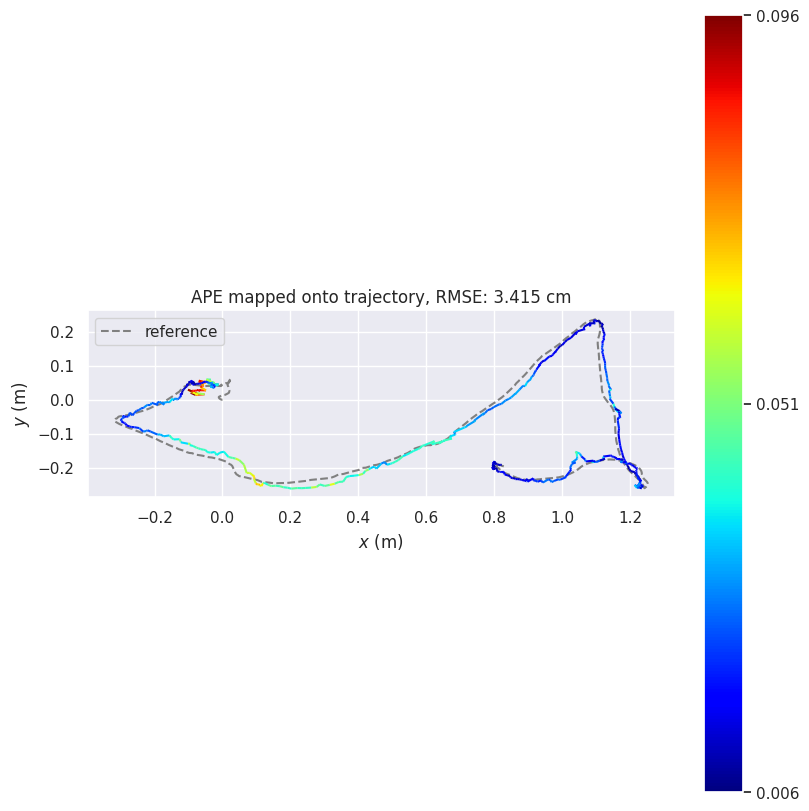


Displaying: Outputs/Bonn/bonn_person_tracking/traj/kf_traj_2d.png


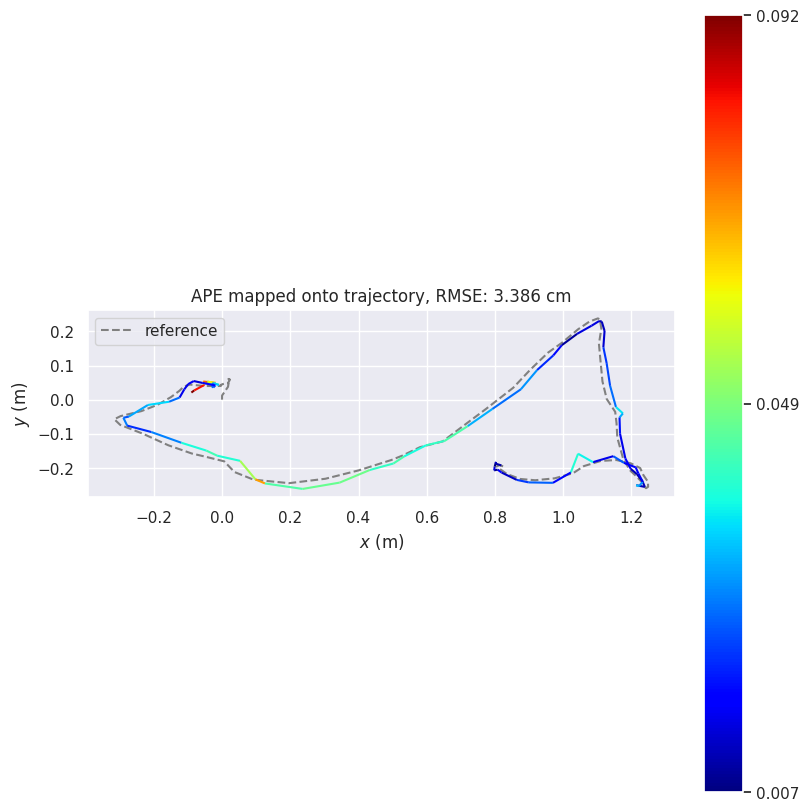


Displaying: Outputs/Bonn/bonn_person_tracking/traj/before_final_ba/kf_traj_2d.png


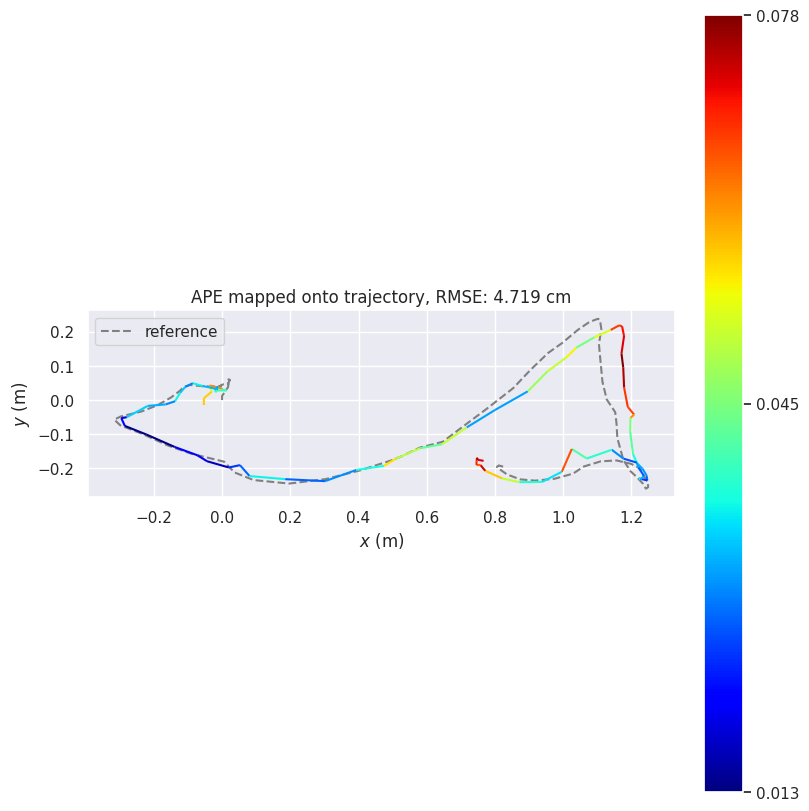

In [115]:
%cd /content/vggt-demo/third_party/DROID-W

from pathlib import Path
from IPython.display import Image, display
import os

OUT = Path("Outputs/Bonn/bonn_person_tracking")

print("==== Metrics files ====")
for p in [
    OUT / "traj/metrics_full_traj.txt",
    OUT / "traj/metrics_kf_traj.txt",
    OUT / "traj/before_final_ba/metrics_kf_traj.txt",
    OUT / "timer_summary.csv",
]:
    print("\n---", p, "---")
    if p.exists():
        print(p.read_text()[:3000])
    else:
        print("Not found")

print("\n==== Available visualization PNGs ====")
pngs = sorted(OUT.rglob("*.png"))
for p in pngs[:80]:
    print(p)

print("\n==== Main trajectory visualizations ====")
for p in [
    OUT / "traj/full_traj_2d.png",
    OUT / "traj/kf_traj_2d.png",
    OUT / "traj/before_final_ba/kf_traj_2d.png",
]:
    if p.exists():
        print("\nDisplaying:", p)
        display(Image(filename=str(p)))

In [121]:
%cd /content/vggt-demo/third_party/DROID-W

from pathlib import Path
import numpy as np

OUT = Path("Outputs/Bonn/bonn_person_tracking")
gt_path = OUT / "gt_poses.txt"
est_path = OUT / "traj/est_poses_full.txt"

gt = np.loadtxt(gt_path)
est = np.loadtxt(est_path)

if gt.ndim == 1:
    gt = gt[None, :]
if est.ndim == 1:
    est = est[None, :]

n = min(len(gt), len(est))
print("GT frames:", len(gt))
print("EST frames:", len(est))
print("Use matched frames:", n)

gt = gt[:n].copy()
est = est[:n].copy()

# Use artificial shared timestamps: 0, 1, 2, ...
shared_t = np.arange(n, dtype=np.float64)

gt_matched = gt.copy()
est_matched = est.copy()

gt_matched[:, 0] = shared_t
est_matched[:, 0] = shared_t

matched_gt_path = OUT / "traj/gt_poses_index_matched.txt"
matched_est_path = OUT / "traj/est_poses_full_index_matched.txt"

np.savetxt(matched_gt_path, gt_matched, fmt="%.9f")
np.savetxt(matched_est_path, est_matched, fmt="%.9f")

print("Saved:")
print(matched_gt_path)
print(matched_est_path)

print("\nMatched GT first 3:")
print(gt_matched[:3])
print("\nMatched EST first 3:")
print(est_matched[:3])

/content/vggt-demo/third_party/DROID-W
GT frames: 580
EST frames: 580
Use matched frames: 580
Saved:
Outputs/Bonn/bonn_person_tracking/traj/gt_poses_index_matched.txt
Outputs/Bonn/bonn_person_tracking/traj/est_poses_full_index_matched.txt

Matched GT first 3:
[[ 0.00000e+00  0.00000e+00  0.00000e+00  0.00000e+00  0.00000e+00
   0.00000e+00  0.00000e+00  1.00000e+00]
 [ 1.00000e+00 -0.00000e+00  0.00000e+00 -0.00000e+00  0.00000e+00
  -0.00000e+00 -0.00000e+00  1.00000e+00]
 [ 2.00000e+00 -2.47000e-03 -3.14000e-04 -1.73900e-03 -1.41600e-03
   1.66600e-03 -2.68900e-03  9.99994e-01]]

Matched EST first 3:
[[ 0.        0.        0.        0.        0.        0.        0.
   1.      ]
 [ 1.        0.010556 -0.004521  0.004512 -0.002181 -0.007449 -0.004848
   0.999958]
 [ 2.        0.030066 -0.002649  0.012687 -0.002513 -0.004767 -0.010199
   0.999933]]


In [122]:
%cd /content/vggt-demo/third_party/DROID-W

!pip install -q evo

print("==== ATE full trajectory, index matched ====")
!evo_ape tum \
  Outputs/Bonn/bonn_person_tracking/traj/gt_poses_index_matched.txt \
  Outputs/Bonn/bonn_person_tracking/traj/est_poses_full_index_matched.txt \
  --align --correct_scale \
  --save_results Outputs/Bonn/bonn_person_tracking/traj/evo_ate_full_index_matched.zip

print("==== RPE translation, index matched ====")
!evo_rpe tum \
  Outputs/Bonn/bonn_person_tracking/traj/gt_poses_index_matched.txt \
  Outputs/Bonn/bonn_person_tracking/traj/est_poses_full_index_matched.txt \
  --align --correct_scale \
  --pose_relation trans_part \
  --save_results Outputs/Bonn/bonn_person_tracking/traj/evo_rpe_trans_index_matched.zip

print("==== RPE rotation, index matched ====")
!evo_rpe tum \
  Outputs/Bonn/bonn_person_tracking/traj/gt_poses_index_matched.txt \
  Outputs/Bonn/bonn_person_tracking/traj/est_poses_full_index_matched.txt \
  --align --correct_scale \
  --pose_relation angle_deg \
  --save_results Outputs/Bonn/bonn_person_tracking/traj/evo_rpe_rot_index_matched.zip

/content/vggt-demo/third_party/DROID-W
==== ATE full trajectory, index matched ====
APE w.r.t. translation part (m)
(with Sim(3) Umeyama alignment)

       max	0.095656
      mean	0.028617
    median	0.023875
       min	0.005557
      rmse	0.034151
       sse	0.676457
       std	0.018637

==== RPE translation, index matched ====
RPE w.r.t. translation part (m)
for delta = 1 (frames) using consecutive pairs
(with Sim(3) Umeyama alignment)

       max	0.039036
      mean	0.008135
    median	0.006450
       min	0.000474
      rmse	0.010132
       sse	0.059438
       std	0.006040

==== RPE rotation, index matched ====
RPE w.r.t. rotation angle in degrees (deg)
for delta = 1 (frames) using consecutive pairs
(with Sim(3) Umeyama alignment)

       max	5.127769
      mean	0.608895
    median	0.370478
       min	0.023084
      rmse	0.892273
       sse	460.971499
       std	0.652225



In [124]:
%cd /content/vggt-demo/third_party/DROID-W

from pathlib import Path

OUT = Path("Outputs/Bonn/bonn_person_tracking")

for p in [
    OUT / "traj/metrics_full_traj.txt",
    OUT / "traj/metrics_kf_traj.txt",
    OUT / "traj/before_final_ba/metrics_kf_traj.txt",
    OUT / "timer_summary.csv",
]:
    print("\n==============================")
    print(p)
    print("==============================")
    if p.exists():
        print(p.read_text())
    else:
        print("Not found")

/content/vggt-demo/third_party/DROID-W

Outputs/Bonn/bonn_person_tracking/traj/metrics_full_traj.txt
##########Full traj##########
scale: 1.3268362615868878
rotation:
[[ 0.99753283  0.02585908  0.06526532]
 [-0.02556519  0.99965892 -0.00533431]
 [-0.065381    0.00365263  0.99785369]]
translation:[-0.09348675  0.02020934 -0.00136366]
statistics:
{'rmse': 0.0341512271148174, 'mean': 0.028617364995244494, 'median': np.float64(0.02387526100488866), 'std': 0.018637401486709313, 'min': np.float64(0.005556829164816198), 'max': np.float64(0.09565588873837293), 'sse': np.float64(0.6764576617997466)}

Outputs/Bonn/bonn_person_tracking/traj/metrics_kf_traj.txt
##########Keyframes traj##########
scale: 1.3237419969187145
rotation:
[[ 0.99759555  0.02539163  0.06448554]
 [-0.02479926  0.99964273 -0.00997001]
 [-0.06471566  0.00834684  0.99786884]]
translation:[-0.08984305  0.02084441 -0.00168633]
statistics:
{'rmse': 0.03386147684524247, 'mean': 0.028630119943650705, 'median': np.float64(0.02498466

/content/vggt-demo/third_party/DROID-W

 Outputs/Bonn/bonn_person_tracking/traj/full_traj_2d.png


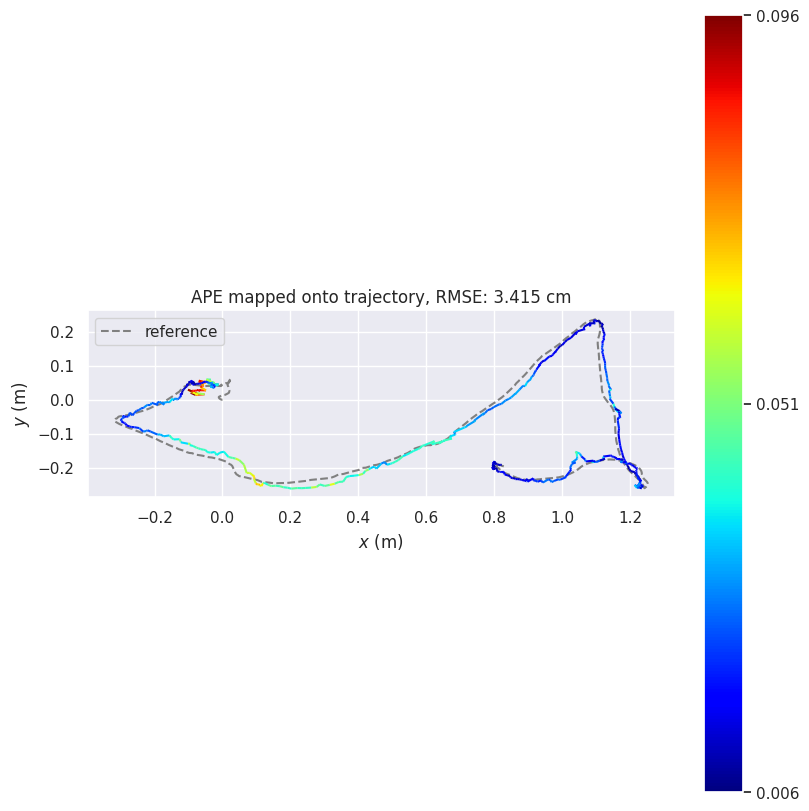


 Outputs/Bonn/bonn_person_tracking/traj/kf_traj_2d.png


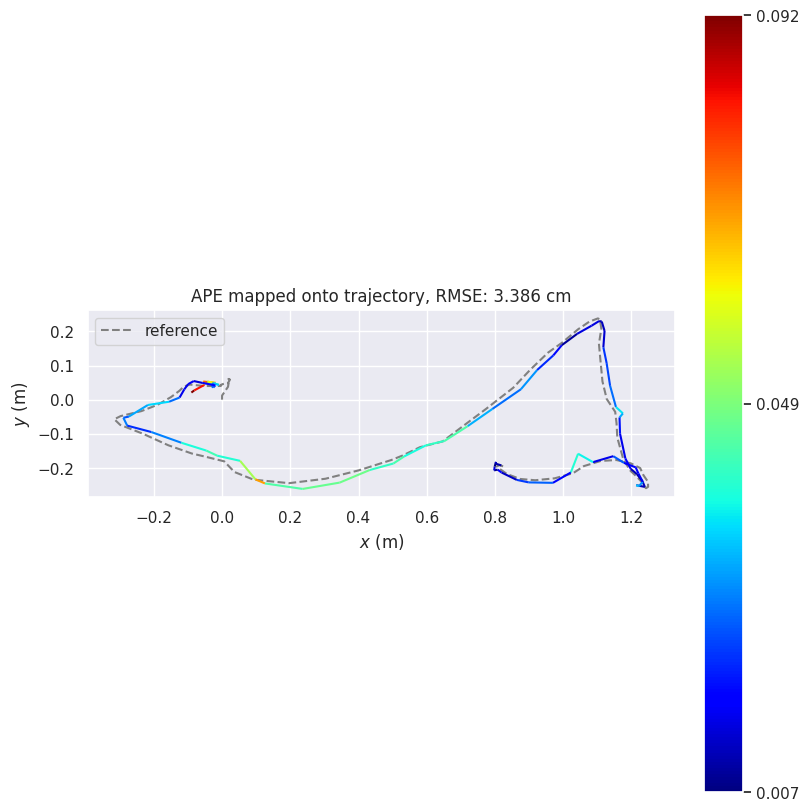


 Outputs/Bonn/bonn_person_tracking/traj/before_final_ba/kf_traj_2d.png


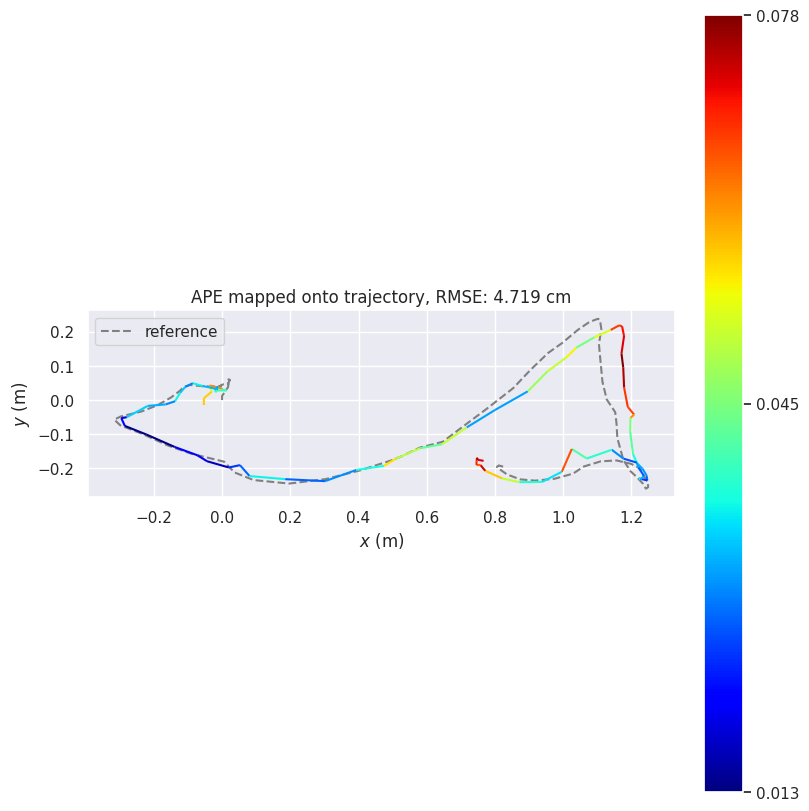

In [123]:
%cd /content/vggt-demo/third_party/DROID-W

from IPython.display import Image, display
from pathlib import Path

OUT = Path("Outputs/Bonn/bonn_person_tracking")

for p in [
    OUT / "traj/full_traj_2d.png",
    OUT / "traj/kf_traj_2d.png",
    OUT / "traj/before_final_ba/kf_traj_2d.png",
]:
    print("\n", p)
    if p.exists():
        display(Image(filename=str(p)))
    else:
        print("Not found")

/content/vggt-demo/third_party/DROID-W
==== Custom ATE after Sim(3) alignment ====
Frames: 580
ATE RMSE:   0.034151 m
ATE mean:   0.028617 m
ATE median: 0.023875 m
ATE max:    0.095656 m
Scale:      1.326836


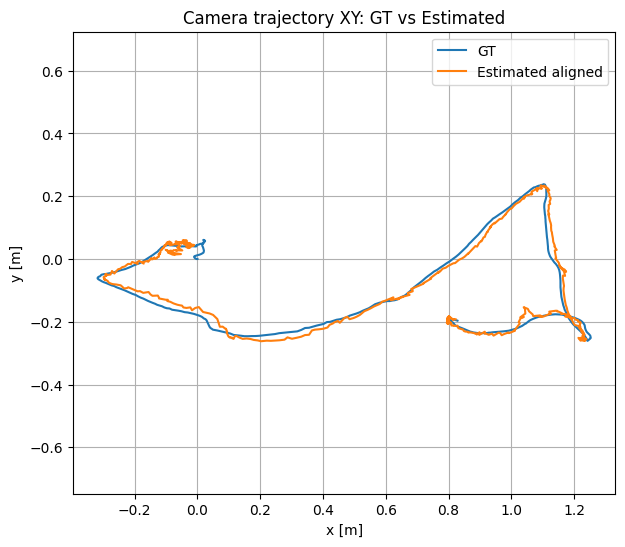

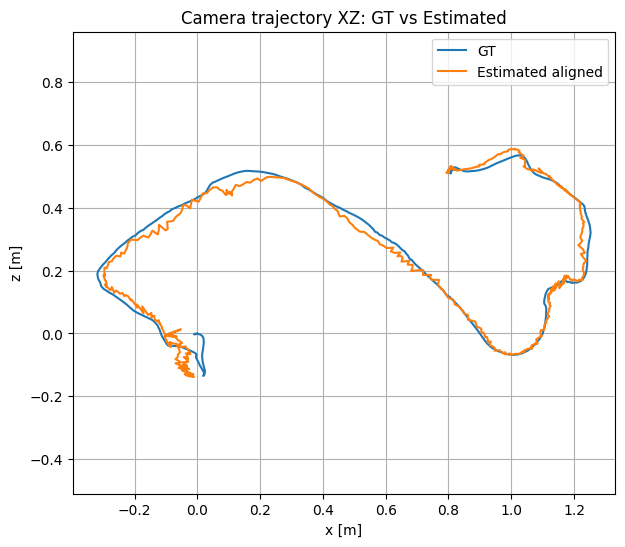

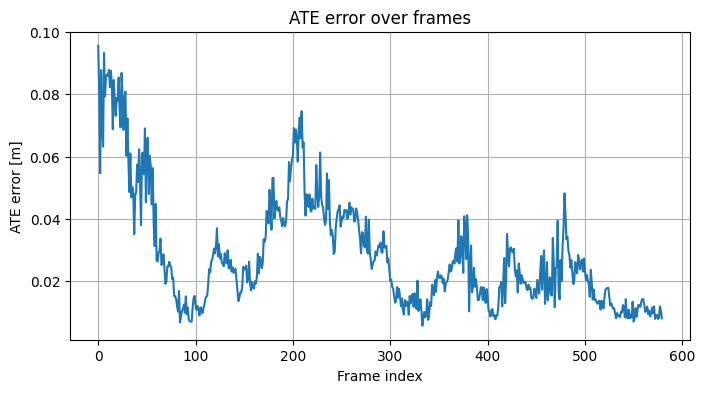

Saved:
Outputs/Bonn/bonn_person_tracking/traj/custom_eval/trajectory_xy_gt_vs_est.png
Outputs/Bonn/bonn_person_tracking/traj/custom_eval/trajectory_xz_gt_vs_est.png
Outputs/Bonn/bonn_person_tracking/traj/custom_eval/ate_error_over_frames.png
Outputs/Bonn/bonn_person_tracking/traj/custom_eval/custom_ate_summary.txt


In [118]:
%cd /content/vggt-demo/third_party/DROID-W

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

OUT = Path("Outputs/Bonn/bonn_person_tracking")
GT_PATH = OUT / "gt_poses.txt"
EST_PATH = OUT / "traj/est_poses_full.txt"
SAVE_DIR = OUT / "traj/custom_eval"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

def load_tum_pose(path):
    data = np.loadtxt(path)
    if data.ndim == 1:
        data = data[None, :]
    # TUM format: timestamp tx ty tz qx qy qz qw
    if data.shape[1] >= 8:
        t = data[:, 0]
        xyz = data[:, 1:4]
    elif data.shape[1] >= 7:
        t = np.arange(len(data))
        xyz = data[:, 0:3]
    else:
        raise ValueError(f"Unsupported pose format: {path}, shape={data.shape}")
    return t, xyz

def umeyama_align(X, Y, with_scale=True):
    """
    Align X to Y using similarity transform.
    X: estimated xyz, Y: GT xyz
    """
    n = X.shape[0]
    mu_x = X.mean(axis=0)
    mu_y = Y.mean(axis=0)
    Xc = X - mu_x
    Yc = Y - mu_y

    cov = (Yc.T @ Xc) / n
    U, D, Vt = np.linalg.svd(cov)
    S = np.eye(3)
    if np.linalg.det(U) * np.linalg.det(Vt) < 0:
        S[-1, -1] = -1

    R = U @ S @ Vt
    if with_scale:
        var_x = (Xc ** 2).sum() / n
        scale = np.trace(np.diag(D) @ S) / var_x
    else:
        scale = 1.0

    tx = mu_y - scale * R @ mu_x
    X_aligned = scale * (X @ R.T) + tx
    return X_aligned, scale, R, tx

gt_t, gt_xyz = load_tum_pose(GT_PATH)
est_t, est_xyz = load_tum_pose(EST_PATH)

n = min(len(gt_xyz), len(est_xyz))
gt_xyz = gt_xyz[:n]
est_xyz = est_xyz[:n]

est_aligned, scale, R, trans = umeyama_align(est_xyz, gt_xyz, with_scale=True)
errors = np.linalg.norm(est_aligned - gt_xyz, axis=1)

rmse = np.sqrt(np.mean(errors ** 2))
mean = np.mean(errors)
median = np.median(errors)
max_err = np.max(errors)

print("==== Custom ATE after Sim(3) alignment ====")
print(f"Frames: {n}")
print(f"ATE RMSE:   {rmse:.6f} m")
print(f"ATE mean:   {mean:.6f} m")
print(f"ATE median: {median:.6f} m")
print(f"ATE max:    {max_err:.6f} m")
print(f"Scale:      {scale:.6f}")

# 2D XY trajectory
plt.figure(figsize=(7, 6))
plt.plot(gt_xyz[:, 0], gt_xyz[:, 1], label="GT")
plt.plot(est_aligned[:, 0], est_aligned[:, 1], label="Estimated aligned")
plt.axis("equal")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title("Camera trajectory XY: GT vs Estimated")
plt.legend()
plt.grid(True)
xy_path = SAVE_DIR / "trajectory_xy_gt_vs_est.png"
plt.savefig(xy_path, dpi=200, bbox_inches="tight")
plt.show()

# XZ trajectory
plt.figure(figsize=(7, 6))
plt.plot(gt_xyz[:, 0], gt_xyz[:, 2], label="GT")
plt.plot(est_aligned[:, 0], est_aligned[:, 2], label="Estimated aligned")
plt.axis("equal")
plt.xlabel("x [m]")
plt.ylabel("z [m]")
plt.title("Camera trajectory XZ: GT vs Estimated")
plt.legend()
plt.grid(True)
xz_path = SAVE_DIR / "trajectory_xz_gt_vs_est.png"
plt.savefig(xz_path, dpi=200, bbox_inches="tight")
plt.show()

# Error over frame
plt.figure(figsize=(8, 4))
plt.plot(errors)
plt.xlabel("Frame index")
plt.ylabel("ATE error [m]")
plt.title("ATE error over frames")
plt.grid(True)
err_path = SAVE_DIR / "ate_error_over_frames.png"
plt.savefig(err_path, dpi=200, bbox_inches="tight")
plt.show()

# Save summary
summary_path = SAVE_DIR / "custom_ate_summary.txt"
summary_path.write_text(
    f"Frames: {n}\n"
    f"ATE RMSE: {rmse:.6f} m\n"
    f"ATE mean: {mean:.6f} m\n"
    f"ATE median: {median:.6f} m\n"
    f"ATE max: {max_err:.6f} m\n"
    f"Scale: {scale:.6f}\n"
)

print("Saved:")
print(xy_path)
print(xz_path)
print(err_path)
print(summary_path)

In [125]:
%%bash
set -e

cd /content/vggt-demo

SAVE_ROOT="/content/drive/MyDrive/vggt_demo_results/bonn_person_tracking_compare"
mkdir -p "$SAVE_ROOT"
mkdir -p /content/vggt-demo/outputs_compare

echo "==== Save current DROID-W output as Ours ===="
rm -rf /content/vggt-demo/outputs_compare/droidw_ours
cp -a /content/vggt-demo/third_party/DROID-W/Outputs/Bonn/bonn_person_tracking \
      /content/vggt-demo/outputs_compare/droidw_ours

rm -rf "$SAVE_ROOT/droidw_ours"
cp -a /content/vggt-demo/third_party/DROID-W/Outputs/Bonn/bonn_person_tracking \
      "$SAVE_ROOT/droidw_ours"

echo "==== Save /content/vggt-demo/outputs as auxiliary outputs ===="
rm -rf "$SAVE_ROOT/vggt_demo_outputs"
cp -a /content/vggt-demo/outputs "$SAVE_ROOT/vggt_demo_outputs"

echo "==== Make zip backups ===="
cd "$SAVE_ROOT"
zip -qr droidw_ours.zip droidw_ours
zip -qr vggt_demo_outputs.zip vggt_demo_outputs

echo "Saved to:"
echo "$SAVE_ROOT/droidw_ours"
echo "$SAVE_ROOT/droidw_ours.zip"
echo "$SAVE_ROOT/vggt_demo_outputs"
echo "$SAVE_ROOT/vggt_demo_outputs.zip"

echo "==== Check copied files ===="
find "$SAVE_ROOT/droidw_ours" -maxdepth 3 -type f | grep -Ei "pose|traj|metric|timer|png|txt|csv" | head -50

==== Save current DROID-W output as Ours ====
==== Save /content/vggt-demo/outputs as auxiliary outputs ====
==== Make zip backups ====
Saved to:
/content/drive/MyDrive/vggt_demo_results/bonn_person_tracking_compare/droidw_ours
/content/drive/MyDrive/vggt_demo_results/bonn_person_tracking_compare/droidw_ours.zip
/content/drive/MyDrive/vggt_demo_results/bonn_person_tracking_compare/vggt_demo_outputs
/content/drive/MyDrive/vggt_demo_results/bonn_person_tracking_compare/vggt_demo_outputs.zip
==== Check copied files ====
/content/drive/MyDrive/vggt_demo_results/bonn_person_tracking_compare/droidw_ours/gt_poses.txt
/content/drive/MyDrive/vggt_demo_results/bonn_person_tracking_compare/droidw_ours/traj/custom_eval/trajectory_xy_gt_vs_est.png
/content/drive/MyDrive/vggt_demo_results/bonn_person_tracking_compare/droidw_ours/traj/custom_eval/trajectory_xz_gt_vs_est.png
/content/drive/MyDrive/vggt_demo_results/bonn_person_tracking_compare/droidw_ours/traj/custom_eval/ate_error_over_frames.png
/co

In [126]:
%%bash
set -e

cd /content/vggt-demo/third_party/DROID-W

TORCH_LIB=$(python - <<'PY'
import torch, os
print(os.path.join(os.path.dirname(torch.__file__), "lib"))
PY
)

export LD_LIBRARY_PATH="$TORCH_LIB:$LD_LIBRARY_PATH"
export PYTHONPATH="/content/vggt-demo/third_party/DROID-W:$PYTHONPATH"

echo "==== Check baseline config should not contain ours static weight ===="
grep -n "ours_dynamic\|static_weight" configs/Dynamic/Bonn/bonn_person_tracking.yaml || true

echo "==== Remove old output ===="
rm -rf Outputs/Bonn/bonn_person_tracking

echo "==== Run original DROID-W baseline ===="
python run.py --config configs/Dynamic/Bonn/bonn_person_tracking.yaml

echo "==== Save baseline output ===="
mkdir -p /content/vggt-demo/outputs_compare
rm -rf /content/vggt-demo/outputs_compare/droidw_baseline
cp -a Outputs/Bonn/bonn_person_tracking /content/vggt-demo/outputs_compare/droidw_baseline

SAVE_ROOT="/content/drive/MyDrive/vggt_demo_results/bonn_person_tracking_compare"
mkdir -p "$SAVE_ROOT"
rm -rf "$SAVE_ROOT/droidw_baseline"
cp -a Outputs/Bonn/bonn_person_tracking "$SAVE_ROOT/droidw_baseline"

cd "$SAVE_ROOT"
zip -qr droidw_baseline.zip droidw_baseline

echo "Saved baseline to:"
echo "/content/vggt-demo/outputs_compare/droidw_baseline"
echo "$SAVE_ROOT/droidw_baseline"
echo "$SAVE_ROOT/droidw_baseline.zip"

==== Check baseline config should not contain ours static weight ====
==== Remove old output ====
==== Run original DROID-W baseline ====
------------------------------
Start WildGS-SLAM at 2026-07-02 23:41:32,
   scene: bonn_dynamic-bonn_person_tracking,
   output: ./Outputs/Bonn/bonn_person_tracking
------------------------------
INFO: GT poses saved to ./Outputs/Bonn/bonn_person_tracking/gt_poses.txt
[INFO] Load droid pretrained checkpoint from ./pretrained/droid.pth!
[TRACKER] Tracking Triggered!
[Timer] Summary (auto) – per decorated function:
  - Tracking: count=580, total=214.209376s, avg=0.369327s, min=0.008327s, max=3.090858s, fps=2.71
  - Metric Depth Estimation: count=129, total=126.990636s, avg=0.984424s, min=0.869634s, max=1.169281s, fps=1.02
  - Full Trajectory Filling: count=1, total=44.970102s, avg=44.970102s, min=44.970102s, max=44.970102s, fps=0.02
  - Final Global BA: count=1, total=44.092007s, avg=44.092007s, min=44.092007s, max=44.092007s, fps=0.02
  - DINO Feature

xFormers not available
xFormers not available
2026-07-02 23:41:28.121516: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
xFormers not available
xFormers not available
xFormers not available
xFormers not available
Using cache found in /root/.cache/torch/hub/yvanyin_metric3d_main
/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/usr/local/lib/python3.12/dist-packages/timm/models/registry.py:4: FutureWarning: Importing from timm.models.registry is deprecated, please import via timm.models
  warnings.warn(f"Importing from {__na

In [127]:
%cd /content/vggt-demo/third_party/DROID-W

from pathlib import Path
import ast
import re
import pandas as pd
import numpy as np
from IPython.display import display

BASE = Path("/content/vggt-demo/outputs_compare/droidw_baseline")
OURS = Path("/content/vggt-demo/outputs_compare/droidw_ours")

def parse_metrics(path):
    text = path.read_text()
    m = re.search(r"statistics:\s*(\{.*\})", text)
    if not m:
        raise ValueError(f"No statistics found in {path}")
    s = m.group(1)
    s = s.replace("np.float64(", "").replace(")", "")
    return ast.literal_eval(s)

base_full = parse_metrics(BASE / "traj/metrics_full_traj.txt")
ours_full = parse_metrics(OURS / "traj/metrics_full_traj.txt")

base_kf = parse_metrics(BASE / "traj/metrics_kf_traj.txt")
ours_kf = parse_metrics(OURS / "traj/metrics_kf_traj.txt")

rows = [
    {
        "Method": "DROID-W baseline",
        "Trajectory": "Full",
        "ATE RMSE [m] ↓": base_full["rmse"],
        "ATE Mean [m] ↓": base_full["mean"],
        "ATE Median [m] ↓": base_full["median"],
        "ATE Max [m] ↓": base_full["max"],
    },
    {
        "Method": "DROID-W + Ours",
        "Trajectory": "Full",
        "ATE RMSE [m] ↓": ours_full["rmse"],
        "ATE Mean [m] ↓": ours_full["mean"],
        "ATE Median [m] ↓": ours_full["median"],
        "ATE Max [m] ↓": ours_full["max"],
    },
    {
        "Method": "DROID-W baseline",
        "Trajectory": "Keyframe",
        "ATE RMSE [m] ↓": base_kf["rmse"],
        "ATE Mean [m] ↓": base_kf["mean"],
        "ATE Median [m] ↓": base_kf["median"],
        "ATE Max [m] ↓": base_kf["max"],
    },
    {
        "Method": "DROID-W + Ours",
        "Trajectory": "Keyframe",
        "ATE RMSE [m] ↓": ours_kf["rmse"],
        "ATE Mean [m] ↓": ours_kf["mean"],
        "ATE Median [m] ↓": ours_kf["median"],
        "ATE Max [m] ↓": ours_kf["max"],
    },
]

df = pd.DataFrame(rows)

improvement_full = {
    "Method": "Improvement",
    "Trajectory": "Full",
    "ATE RMSE [m] ↓": base_full["rmse"] - ours_full["rmse"],
    "ATE Mean [m] ↓": base_full["mean"] - ours_full["mean"],
    "ATE Median [m] ↓": base_full["median"] - ours_full["median"],
    "ATE Max [m] ↓": base_full["max"] - ours_full["max"],
}

improvement_percent_full = {
    "Method": "Improvement %",
    "Trajectory": "Full",
    "ATE RMSE [m] ↓": (base_full["rmse"] - ours_full["rmse"]) / base_full["rmse"] * 100,
    "ATE Mean [m] ↓": (base_full["mean"] - ours_full["mean"]) / base_full["mean"] * 100,
    "ATE Median [m] ↓": (base_full["median"] - ours_full["median"]) / base_full["median"] * 100,
    "ATE Max [m] ↓": (base_full["max"] - ours_full["max"]) / base_full["max"] * 100,
}

df = pd.concat([df, pd.DataFrame([improvement_full, improvement_percent_full])], ignore_index=True)

display(df)

save_dir = Path("/content/vggt-demo/outputs_compare/eval")
save_dir.mkdir(parents=True, exist_ok=True)
df.to_csv(save_dir / "droidw_baseline_vs_ours_ate_metrics.csv", index=False)

print("Saved:", save_dir / "droidw_baseline_vs_ours_ate_metrics.csv")

/content/vggt-demo/third_party/DROID-W


,Method,Trajectory,ATE RMSE [m] ↓,ATE Mean [m] ↓,ATE Median [m] ↓,ATE Max [m] ↓
0,DROID-W baseline,Full,0.034173,0.028679,0.023976,0.094811
1,DROID-W + Ours,Full,0.034151,0.028617,0.023875,0.095656
2,DROID-W baseline,Keyframe,0.033820,0.028643,0.025037,0.091474
3,DROID-W + Ours,Keyframe,0.033861,0.028630,0.024985,0.092245
4,Improvement,Full,0.000022,0.000061,0.000101,-0.000845
5,Improvement %,Full,0.065004,0.214327,0.420998,-0.891192


Saved: /content/vggt-demo/outputs_compare/eval/droidw_baseline_vs_ours_ate_metrics.csv


/content/vggt-demo/third_party/DROID-W


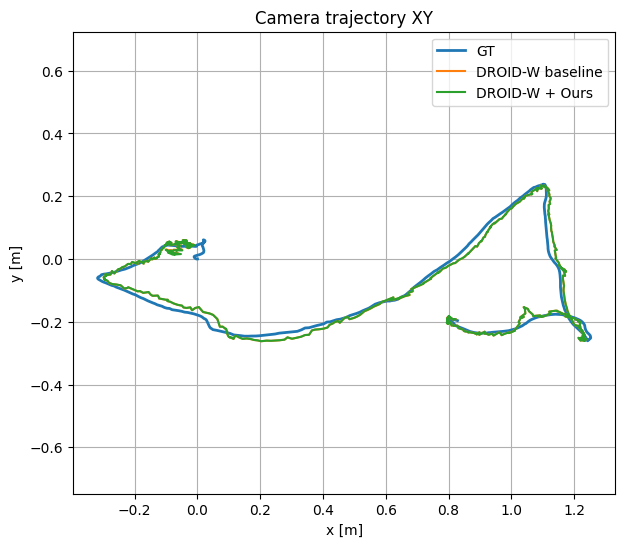

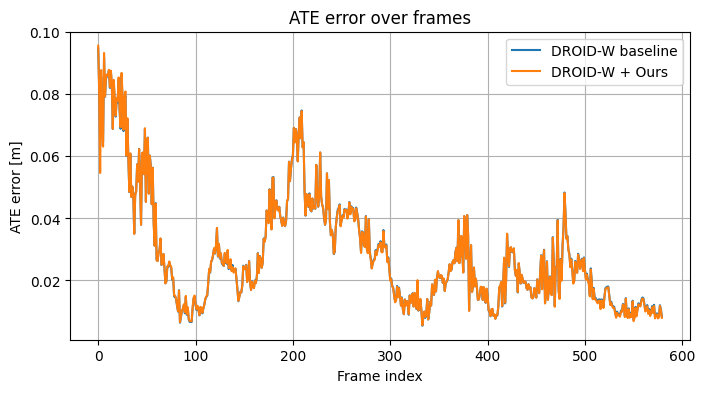

Saved:
/content/vggt-demo/outputs_compare/eval/trajectory_xy_baseline_vs_ours.png
/content/vggt-demo/outputs_compare/eval/ate_error_baseline_vs_ours.png


In [128]:
%cd /content/vggt-demo/third_party/DROID-W

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image

BASE = Path("/content/vggt-demo/outputs_compare/droidw_baseline")
OURS = Path("/content/vggt-demo/outputs_compare/droidw_ours")
SAVE_DIR = Path("/content/vggt-demo/outputs_compare/eval")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

def load_tum_xyz(path):
    data = np.loadtxt(path)
    if data.ndim == 1:
        data = data[None, :]
    return data[:, 1:4]

def umeyama_align(X, Y, with_scale=True):
    n = min(len(X), len(Y))
    X = X[:n]
    Y = Y[:n]
    mu_x = X.mean(axis=0)
    mu_y = Y.mean(axis=0)
    Xc = X - mu_x
    Yc = Y - mu_y
    cov = (Yc.T @ Xc) / n
    U, D, Vt = np.linalg.svd(cov)
    S = np.eye(3)
    if np.linalg.det(U) * np.linalg.det(Vt) < 0:
        S[-1, -1] = -1
    R = U @ S @ Vt
    if with_scale:
        var_x = (Xc ** 2).sum() / n
        scale = np.trace(np.diag(D) @ S) / var_x
    else:
        scale = 1.0
    t = mu_y - scale * R @ mu_x
    X_aligned = scale * (X @ R.T) + t
    return X_aligned

gt = load_tum_xyz(BASE / "gt_poses.txt")
base_est = load_tum_xyz(BASE / "traj/est_poses_full.txt")
ours_est = load_tum_xyz(OURS / "traj/est_poses_full.txt")

n = min(len(gt), len(base_est), len(ours_est))
gt = gt[:n]
base_est = base_est[:n]
ours_est = ours_est[:n]

base_aligned = umeyama_align(base_est, gt)
ours_aligned = umeyama_align(ours_est, gt)

base_err = np.linalg.norm(base_aligned - gt, axis=1)
ours_err = np.linalg.norm(ours_aligned - gt, axis=1)

plt.figure(figsize=(7, 6))
plt.plot(gt[:, 0], gt[:, 1], label="GT", linewidth=2)
plt.plot(base_aligned[:, 0], base_aligned[:, 1], label="DROID-W baseline")
plt.plot(ours_aligned[:, 0], ours_aligned[:, 1], label="DROID-W + Ours")
plt.axis("equal")
plt.grid(True)
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title("Camera trajectory XY")
plt.legend()
xy_path = SAVE_DIR / "trajectory_xy_baseline_vs_ours.png"
plt.savefig(xy_path, dpi=220, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(base_err, label="DROID-W baseline")
plt.plot(ours_err, label="DROID-W + Ours")
plt.grid(True)
plt.xlabel("Frame index")
plt.ylabel("ATE error [m]")
plt.title("ATE error over frames")
plt.legend()
err_path = SAVE_DIR / "ate_error_baseline_vs_ours.png"
plt.savefig(err_path, dpi=220, bbox_inches="tight")
plt.show()

print("Saved:")
print(xy_path)
print(err_path)

## 13. Download DROID-W static weights and Bonn point-level outputs

In [ ]:
import shutil
from pathlib import Path
from google.colab import files

targets = [
    Path("/content/vggt-demo/outputs/ours_bonn_person_temporal16"),
    Path("/content/vggt-demo/outputs/droidw_ours_weights/person_tracking"),
]

for target in targets:
    assert target.exists(), f"Missing: {target}"
    zip_base = Path("/content") / target.name
    shutil.make_archive(str(zip_base), "zip", root_dir=target)
    print("Downloading:", str(zip_base) + ".zip")
    files.download(str(zip_base) + ".zip")


## 9. Optional: push branch from Colab

Only run this after configuring GitHub authentication. Do not paste tokens into notebook outputs.

In [ ]:
# !git config user.name "ZexuZang"
# !git config user.email "zexuzang1@gmail.com"
# !git checkout -b any4d-dynamic-mask
# !git add scripts/any4d_mask notebooks/VGGT_Any4D_Dynamic_Mask_Colab.ipynb docs/VGGT_ANY4D_DYNAMIC_MASK.md
# !git commit -m "Add Any4D dynamic mask refinement for VGGT"
# !git push origin any4d-dynamic-mask
